# HW4 — Sector-Aware ML Strategy: Final Walk-Forward Backtest
## Notebook 2 of 2: Full-Universe Final Test, April 2016 – September 2026

This notebook runs the strategy fixed in `HW4_Strategy2_Sector_Aware_ML.ipynb` (notebook 1) on the full homework database `equities_top2000.duckdb`, using a custom daily backtester.

**Strategy (frozen in notebook 1)**
- **50% growth sleeve:** highest predicted positive 90-day return in each sector.
- **50% defensive sleeve:** within each sector, keep the lowest-volatility 40% of eligible names and choose the highest predicted positive-return name.
- No duplicate symbols across sleeves.
- Maximum 10% of portfolio value per symbol and 20% per sector, measured at the signal-date close.
- Monthly signals at the last supplied market session of each month; features use information through the signal close.
- Purchase at the next market session's close.
- Hold 90 calendar days; sell at the first market session on/after maturity with an actual quote, within a five-session quote tolerance.
- Long-only, no leverage, $1,000,000 starting capital.

**Workflow**
1. Load the frozen model choice and training settings saved by notebook 1.
2. Build month-end feature/label rows for every stock in the full database, in symbol batches.
3. Fit the selected model before the first test entry, using only 2010–2016 month-end observations whose 90-day outcomes ended before the March 31, 2016 signal.
4. Refit once per year at the last December signal, using only outcomes that ended before that fit date.
5. Generate out-of-sample monthly picks and simulate purchases, sales, cash, open lots and daily portfolio value.
6. Compare the portfolio with $1,000,000 invested in `^SP500TR` at the first test close.

**Training sample.** Development validation trained on every daily row. The final fits use the month-end rows only, which keeps the full-universe panel small enough to build and fit. Daily rows within a month share almost the same 90-day outcome, so the month-end rows keep most of the information.

**Important limitations**
- The supplied `sector` field is a current snapshot, not a historical classification. It is used for portfolio grouping only, not as a model feature.
- Financial statements are vendor latest values, not original filing vintages, and the data are not a certified survivorship-free constituent or corporate-action feed.
- Monthly 90-day cohort returns overlap and are not a compounded portfolio return. The daily backtester below is the source for all final portfolio metrics.

**Course code attribution**

This notebook reuses `Lectures/modeling/course_data.py` for reading the database, historical price features, availability-dated fundamental features, quarterly membership mapping, next-session 90-day labels and the train-fitted preprocessing pipeline. The batch orchestration, sector-sleeve selector, daily portfolio ledger and accounting tests are custom HW4 code.

## 1. Imports and paths

In [1]:
from pathlib import Path
import sys
import json
import math

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.5f}")

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for path in [start, *start.parents]:
        if (path / "Lectures" / "modeling" / "data").is_dir():
            return path
    raise FileNotFoundError("Could not locate repository root.")

ROOT = find_project_root()
MODELING_DIR = ROOT / "Lectures" / "modeling"
DATA_DIR = MODELING_DIR / "data"

CLASS_DB = DATA_DIR / "equities_class.duckdb"
FULL_DB = DATA_DIR / "equities_top2000.duckdb"

assert CLASS_DB.exists(), f"Missing classroom DB: {CLASS_DB}"
assert FULL_DB.exists(), f"Missing full homework DB: {FULL_DB}"
assert (MODELING_DIR / "course_data.py").exists(), "course_data.py not found"

if str(MODELING_DIR) not in sys.path:
    sys.path.insert(0, str(MODELING_DIR))

from course_data import (
    load_data,
    price_features,
    load_membership,
    apply_membership,
    financial_events,
    join_financials,
    make_labels,
    prepare_panel,
    make_pipeline as make_course_pipeline,
    NUMERIC_FEATURES,
)

FEATURE_COLUMNS = list(NUMERIC_FEATURES)

OUTPUT_DIR = MODELING_DIR / "outputs" / "hw4_final"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Frozen development configuration written by notebook 1.
DEV_CONFIG_PATH = MODELING_DIR / "outputs" / "hw4_development" / "strategy_config.json"

# Small result files (chart and metrics table) are also saved next to this notebook.
SUBMISSION_DIR = ROOT / "Homeworks" / "HW4" / "Vanditha_Toleti"
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

print("Repository:", ROOT)
print("Class database:", CLASS_DB)
print("Full database:", FULL_DB)
print("Output directory:", OUTPUT_DIR)
print("Numeric features:", FEATURE_COLUMNS)

Repository: /Users/vandu/UCB-MFE-python-preprogram-2026-winter
Class database: /Users/vandu/UCB-MFE-python-preprogram-2026-winter/Lectures/modeling/data/equities_class.duckdb
Full database: /Users/vandu/UCB-MFE-python-preprogram-2026-winter/Lectures/modeling/data/equities_top2000.duckdb
Output directory: /Users/vandu/UCB-MFE-python-preprogram-2026-winter/Lectures/modeling/outputs/hw4_final
Numeric features: ['momentum_21', 'momentum_63', 'momentum_252_21', 'volatility_63', 'drawdown_252', 'net_margin', 'operating_roa', 'debt_to_assets', 'cash_to_assets', 'fcf_to_assets', 'accruals_to_assets', 'filing_age_days']


## 2. Freeze the strategy and backtest assumptions

In [2]:
# Fixed study periods
DEV_START = pd.Timestamp("2010-01-01")
DEV_END = pd.Timestamp("2015-12-31")
BUFFER_END = pd.Timestamp("2016-03-31")

TEST_START = pd.Timestamp("2016-04-01")
TEST_END = pd.Timestamp("2026-09-30")

VALIDATION_YEARS = [2013, 2014, 2015]

# Monthly signal strategy
HOLDING_DAYS = 90
MAX_EXIT_DELAY_SESSIONS = 5

# Portfolio constraints
INITIAL_CAPITAL = 1_000_000.0
GROWTH_SLEEVE_SHARE = 0.50
DEFENSIVE_SLEEVE_SHARE = 0.50
DEFENSIVE_VOLATILITY_QUANTILE = 0.40
MAX_POSITION_WEIGHT = 0.10
MAX_SECTOR_WEIGHT = 0.20

# Backtest cost and financing assumptions
TRANSACTION_COST_BPS = 10.0
TRANSACTION_COST_RATE = TRANSACTION_COST_BPS / 10_000
ANNUAL_CASH_RATE = 0.0
RISK_FREE_RATE = 0.02
ANNUALIZATION = 252  # trading sessions per year for daily Sharpe

# Orders smaller than this are skipped instead of creating dust positions.
MIN_ORDER_NOTIONAL = 100.0

# Memory/runtime setting for full database batches
SYMBOL_BATCH_SIZE = 75
FULL_DATA_END = "2026-09-30"

# Rebuild the full monthly panel only if no cached copy exists.
# Set True to force a rebuild from the database.
REBUILD_FULL_MONTHLY_PANEL = False

assert abs(GROWTH_SLEEVE_SHARE + DEFENSIVE_SLEEVE_SHARE - 1.0) < 1e-12
assert INITIAL_CAPITAL > 0
assert TRANSACTION_COST_RATE >= 0

ASSUMPTIONS = {
    "signal_schedule": "last supplied market session of each month",
    "feature_cutoff": "signal-date close",
    "entry": "next market session close",
    "holding_period": "90 calendar days",
    "exit": "first market session on/after maturity with an actual quote; at most 5-session quote delay",
    "growth_sleeve": "50%; highest predicted positive-return stock per sector",
    "defensive_sleeve": "50%; within-sector lowest-volatility 40%, then highest predicted positive-return stock",
    "position_cap": "10% of signal-date NAV per ticker, using signal-date marks",
    "sector_cap": "20% of signal-date NAV per sector, using signal-date marks",
    "order_sizing": "sleeve weight x signal-date NAV, reduced by caps and available cash",
    "minimum_order": f"${MIN_ORDER_NOTIONAL:,.0f}",
    "transaction_cost": f"{TRANSACTION_COST_BPS:.1f} bps per buy and sell",
    "cash_interest": f"{ANNUAL_CASH_RATE:.2%} annually",
    "fractional_shares": True,
    "missing_prices": "no fill without an actual quote; skipped entries are logged",
    "stale_marks": "carry forward last observed adjusted close for NAV only; do not use as execution price",
    "unsold_lots": "a lot with no quote within 5 sessions of maturity stays open at its last observed price",
    "annual_refit": "initial fit at 2016-03-31; then last market session of December each year",
}
display(pd.Series(ASSUMPTIONS, name="assumption").to_frame())

,assumption
signal_schedule,last supplied market session of each month
feature_cutoff,signal-date close
entry,next market session close
holding_period,90 calendar days
exit,first market session on/after maturity with an...
growth_sleeve,50%; highest predicted positive-return stock p...
defensive_sleeve,"50%; within-sector lowest-volatility 40%, then..."
position_cap,"10% of signal-date NAV per ticker, using signa..."
sector_cap,"20% of signal-date NAV per sector, using signa..."
order_sizing,"sleeve weight x signal-date NAV, reduced by ca..."


## 3. Define model candidates

We use the same model families and hyperparameters as the development notebook. The model family is selected from 2013–2015 **monthly** chronological validation so the model-selection sample matches the monthly strategy cadence.

In [3]:
MODEL_FACTORIES = {
    "Ridge": lambda: Ridge(alpha=100.0),
    "RandomForest": lambda: RandomForestRegressor(
        n_estimators=250,
        max_depth=5,
        min_samples_leaf=10,
        max_features=0.8,
        n_jobs=-1,
        random_state=42
    ),
    "HistGradientBoosting": lambda: HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_iter=150,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    )
}

def build_model_pipeline(model_name):
    if model_name not in MODEL_FACTORIES:
        raise KeyError(f"Unknown model: {model_name}")
    return make_course_pipeline(
        model=MODEL_FACTORIES[model_name](),
        numeric_features=FEATURE_COLUMNS,
        include_sector=False
    )

print("Candidate models:", list(MODEL_FACTORIES))

Candidate models: ['Ridge', 'RandomForest', 'HistGradientBoosting']


## 4. Load the frozen development configuration

Notebook 1 chose the model and fixed the training settings using the 2013–2015 validation folds only. We load that configuration instead of re-selecting anything here, and check that the strategy constants in this notebook match it exactly.

In [4]:
if not DEV_CONFIG_PATH.exists():
    raise FileNotFoundError(
        f"Missing {DEV_CONFIG_PATH}. Run HW4_Strategy2_Sector_Aware_ML.ipynb first."
    )

with open(DEV_CONFIG_PATH, encoding="utf-8") as f:
    DEV_CONFIG = json.load(f)

SELECTED_MODEL_NAME = DEV_CONFIG["selected_model"]
TARGET_CLIP_QUANTILES = tuple(DEV_CONFIG["training_target_clip_quantiles"])

frozen_checks = {
    "holding_days_calendar": HOLDING_DAYS,
    "max_exit_delay_sessions": MAX_EXIT_DELAY_SESSIONS,
    "growth_sleeve_share": GROWTH_SLEEVE_SHARE,
    "defensive_sleeve_share": DEFENSIVE_SLEEVE_SHARE,
    "defensive_volatility_quantile_within_sector": DEFENSIVE_VOLATILITY_QUANTILE,
    "max_position_weight": MAX_POSITION_WEIGHT,
    "max_sector_weight": MAX_SECTOR_WEIGHT,
}
for key, value in frozen_checks.items():
    assert DEV_CONFIG[key] == value, f"{key} differs from the frozen development configuration"

assert DEV_CONFIG["model_feature_columns"] == FEATURE_COLUMNS
assert SELECTED_MODEL_NAME in MODEL_FACTORIES

display(pd.Series({
    "selected_model": SELECTED_MODEL_NAME,
    "model_selection_metric": DEV_CONFIG["model_selection_metric"],
    "training_target_clip_quantiles": TARGET_CLIP_QUANTILES,
    "refit_schedule": DEV_CONFIG["refit_schedule"],
}, name="frozen value").to_frame())

,frozen value
selected_model,RandomForest
model_selection_metric,highest mean daily Spearman Rank IC across 201...
training_target_clip_quantiles,"(0.01, 0.99)"
refit_schedule,"once per calendar year, before that year's fir..."


## 5. Monthly signal dates

A signal is generated at the last supplied market session of each calendar month. The next supplied market session is the entry date.

The March 31, 2016 signal is included as the initial pre-test signal because its next-session close is the first final-test close (April 1, 2016).

In [5]:
def month_end_signals(calendar_dates):
    calendar_dates = pd.DatetimeIndex(pd.to_datetime(calendar_dates)).sort_values()
    frame = pd.DataFrame({"date": calendar_dates})
    return (
        frame.assign(month=frame["date"].dt.to_period("M"))
        .groupby("month")["date"]
        .max()
        .sort_values()
        .tolist()
    )

## 6. Full-database monthly signal dates and metadata

From this point onward, the notebook uses the full homework database for the **final test only**. It is read in small symbol batches. We do not load the full 15.8-million-row price table into one Pandas DataFrame.

In [6]:
with duckdb.connect(str(FULL_DB), read_only=True) as con:
    full_symbols = con.execute(
        "SELECT symbol FROM universe ORDER BY symbol"
    ).fetchdf()["symbol"].tolist()

    full_benchmark = con.execute("""
        SELECT date, adj_close
        FROM benchmark
        WHERE date <= ?
        ORDER BY date
    """, [FULL_DATA_END]).fetchdf()

full_benchmark["date"] = pd.to_datetime(full_benchmark["date"])
full_calendar = pd.DatetimeIndex(
    full_benchmark["date"].drop_duplicates().sort_values()
)

full_monthly_signals = month_end_signals(full_calendar)
full_monthly_signal_set = set(full_monthly_signals)

full_membership = load_membership(
    database=FULL_DB,
    end=FULL_DATA_END
)

print("Full-universe symbols:", len(full_symbols))
print("Benchmark sessions:", len(full_calendar))
print("Monthly signal dates:", len(full_monthly_signals))
print("Membership records:", len(full_membership))
print("Full benchmark range:", full_calendar.min(), "to", full_calendar.max())

Full-universe symbols: 3849
Benchmark sessions: 6726
Monthly signal dates: 321
Membership records: 195970
Full benchmark range: 2000-01-03 00:00:00 to 2026-09-30 00:00:00


## 7. Build the full monthly feature/label panel in symbol batches

For each batch:
1. Load all available history for those symbols up to September 30, 2026.
2. Compute historical price features over the entire available calendar so pre-2010 history warms up lookbacks.
3. Join availability-dated quarterly financial features.
4. Attach the membership applicable to the next-session entry quarter.
5. Keep only monthly signal dates from 2010 onward.
6. Create the 90-calendar-day next-session labels for audit/training.

The batch is reduced to the required columns before it is kept in memory. We preserve inactive securities and do not screen on future price coverage.

In [7]:
FULL_MONTHLY_CACHE = OUTPUT_DIR / "full_monthly_panel.parquet"

def build_full_monthly_panel(
    database,
    symbols,
    membership,
    monthly_signal_set,
    end_date,
    batch_size=75
):
    batches = []

    keep_columns = list(dict.fromkeys(
        [
            "date", "symbol", "sector",
            "eligible", "is_universe_member",
            "universe_selection_date",
            "entry_date", "entry_price",
            "scheduled_exit", "label_end",
            "exit_price", "target"
        ] + FEATURE_COLUMNS + ["volatility_63"]
    ))

    total_batches = math.ceil(len(symbols) / batch_size)

    for batch_number, start in enumerate(
        range(0, len(symbols), batch_size), start=1
    ):
        batch_symbols = symbols[start:start + batch_size]

        prices_batch, fundamentals_batch, universe_batch, benchmark_batch = load_data(
            database=database,
            end=end_date,
            symbols=batch_symbols
        )

        calendar_batch = pd.DatetimeIndex(
            pd.to_datetime(benchmark_batch["date"])
        )

        # Historical price features are calculated before filtering signal dates.
        price_panel = price_features(prices_batch, calendar_batch)

        financial_batch = financial_events(fundamentals_batch)
        joined_panel = join_financials(
            price_panel,
            financial_batch,
            universe_batch
        )

        membership_batch = membership.loc[
            membership["symbol"].isin(batch_symbols)
        ].copy()

        joined_panel = apply_membership(
            joined_panel,
            membership_batch,
            calendar_batch
        )

        monthly_rows = joined_panel.loc[
            joined_panel["date"].isin(monthly_signal_set)
            & joined_panel["date"].ge(DEV_START)
        ].copy()

        labelled_monthly = make_labels(
            monthly_rows,
            prices_batch,
            calendar_batch,
            holding_days=HOLDING_DAYS,
            max_exit_delay=MAX_EXIT_DELAY_SESSIONS
        )

        # Keep only the compact research panel.
        missing = [c for c in keep_columns if c not in labelled_monthly.columns]
        if missing:
            raise KeyError(f"Batch missing expected columns: {missing}")

        compact = labelled_monthly[keep_columns].copy()
        batches.append(compact)

        if batch_number == 1 or batch_number % 5 == 0 or batch_number == total_batches:
            print(
                f"Batch {batch_number}/{total_batches}: "
                f"{len(batch_symbols)} symbols, "
                f"{len(compact):,} monthly rows"
            )

        del prices_batch, fundamentals_batch, universe_batch
        del price_panel, financial_batch, joined_panel
        del labelled_monthly, compact

    result = pd.concat(batches, ignore_index=True)
    result = result.sort_values(["date", "symbol"]).reset_index(drop=True)

    if result.duplicated(["date", "symbol"]).any():
        raise ValueError("Duplicate (date, symbol) rows found in full monthly panel.")

    return result


if REBUILD_FULL_MONTHLY_PANEL or not FULL_MONTHLY_CACHE.exists():
    full_monthly_panel = build_full_monthly_panel(
        database=FULL_DB,
        symbols=full_symbols,
        membership=full_membership,
        monthly_signal_set=full_monthly_signal_set,
        end_date=FULL_DATA_END,
        batch_size=SYMBOL_BATCH_SIZE
    )

    with duckdb.connect() as cache_con:
        cache_con.register("monthly_panel_df", full_monthly_panel)
        cache_path_sql = str(FULL_MONTHLY_CACHE).replace("'", "''")
        cache_con.execute(
            f"COPY monthly_panel_df TO '{cache_path_sql}' "
            "(FORMAT PARQUET, COMPRESSION ZSTD)"
        )
else:
    cache_path_sql = str(FULL_MONTHLY_CACHE).replace("'", "''")
    with duckdb.connect() as cache_con:
        full_monthly_panel = cache_con.execute(
            f"SELECT * FROM read_parquet('{cache_path_sql}')"
        ).fetchdf()

print("Full monthly panel:", full_monthly_panel.shape)
print("Cache:", FULL_MONTHLY_CACHE)
display(full_monthly_panel.head())

Full monthly panel: (552150, 24)
Cache: /Users/vandu/UCB-MFE-python-preprogram-2026-winter/Lectures/modeling/outputs/hw4_final/full_monthly_panel.parquet


,date,symbol,sector,eligible,is_universe_member,universe_selection_date,entry_date,entry_price,scheduled_exit,label_end,exit_price,target,momentum_21,momentum_63,momentum_252_21,volatility_63,drawdown_252,net_margin,operating_roa,debt_to_assets,cash_to_assets,fcf_to_assets,accruals_to_assets,filing_age_days
0,2010-01-29,A,Healthcare,True,True,2009-12-31,2010-02-01,18.43000,2010-05-02,2010-05-03,23.26000,0.26207,-0.07608,0.10674,0.63319,0.24738,-0.10455,0.02142,0.00933,0.38163,0.32567,0.02404,-0.02470,38.00000
1,2010-01-29,AA,Basic Materials,False,False,NaT,2010-02-01,26.35000,2010-05-02,2010-05-03,25.99000,-0.01366,-0.20595,0.06945,0.95849,0.52966,-0.27056,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2010-01-29,AAIC,Real Estate,True,True,2009-12-31,2010-02-01,3.62085,2010-05-02,2010-05-03,5.09868,0.40815,-0.02139,0.29281,3.28611,0.43159,-0.06790,1.84300,0.06410,0.05935,0.04694,-0.01398,0.16377,80.00000
3,2010-01-29,AAL,Industrials,True,True,2009-12-31,2010-02-01,5.27935,2010-05-02,2010-05-03,6.96686,0.31964,0.09485,0.69649,-0.25039,0.70933,-0.07972,-0.07002,-0.00753,0.58888,0.00664,-0.01992,-0.01347,99.00000
4,2010-01-29,AAN,Industrials,True,True,2009-12-31,2010-02-01,27.93000,2010-05-02,2010-05-03,22.68000,-0.18797,-0.01798,0.11798,NaN,0.24633,NaN,0.05937,0.02854,0.04388,0.06985,0.02329,-0.02429,84.00000


## 8. Audit the full monthly panel and final-test entry boundary

The first final-test close is the first market session on/after April 1, 2016. The initial signal is the immediately preceding monthly signal. The signal date is used to fit/predict; the next session is the first possible fill.

In [8]:
TEST_START_ACTUAL = full_calendar[full_calendar >= TEST_START][0]
TEST_END_ACTUAL = full_calendar[full_calendar <= TEST_END][-1]

initial_signal_candidates = [
    d for d in full_monthly_signals if d < TEST_START_ACTUAL
]
INITIAL_FIT_SIGNAL = initial_signal_candidates[-1]

initial_rows = full_monthly_panel.loc[
    full_monthly_panel["date"].eq(INITIAL_FIT_SIGNAL)
]

print("First final-test market session:", TEST_START_ACTUAL)
print("Last final-test market session:", TEST_END_ACTUAL)
print("Initial pre-test signal:", INITIAL_FIT_SIGNAL)

initial_entry_dates = initial_rows["entry_date"].dropna().unique()
print("Initial signal's next-session entry date(s):", initial_entry_dates)

assert len(initial_entry_dates) == 1
assert pd.Timestamp(initial_entry_dates[0]) == TEST_START_ACTUAL

full_panel_audit = pd.DataFrame({
    "check": [
        "Full monthly rows",
        "Unique symbols observed at monthly signals",
        "Monthly signal dates",
        "Eligible and universe-member rows",
        "Completed target rows",
        "Missing target rows"
    ],
    "count": [
        len(full_monthly_panel),
        full_monthly_panel["symbol"].nunique(),
        full_monthly_panel["date"].nunique(),
        int((full_monthly_panel["eligible"] & full_monthly_panel["is_universe_member"]).sum()),
        int(full_monthly_panel["target"].notna().sum()),
        int(full_monthly_panel["target"].isna().sum())
    ]
})
display(full_panel_audit)

First final-test market session: 2016-04-01 00:00:00
Last final-test market session: 2026-09-30 00:00:00
Initial pre-test signal: 2016-03-31 00:00:00
Initial signal's next-session entry date(s): <DatetimeArray>
['2016-04-01 00:00:00']
Length: 1, dtype: datetime64[ns]


,check,count
0,Full monthly rows,552150
1,Unique symbols observed at monthly signals,3848
2,Monthly signal dates,201
3,Eligible and universe-member rows,395345
4,Completed target rows,539779
5,Missing target rows,12371


## 9. Determine annual model refit dates

The first model is fitted at the March 31, 2016 signal, immediately before the April 1 final-test entry.

The model is then refitted at each year's last December signal date (2016–2025). The newly fitted model predicts that December signal and subsequent monthly signals until the next annual refit. This matches the annual fold-fit convention used in development.

At every fit, the training set includes only monthly signal observations from 2010 onward whose `label_end` is **strictly before** the fit date.

In [9]:
december_refit_dates = [
    d for d in full_monthly_signals
    if d.year in range(2016, 2026) and d.month == 12
]

FIT_DATES = sorted(set([INITIAL_FIT_SIGNAL] + december_refit_dates))

print("Model fit dates:")
display(pd.DataFrame({"fit_date": FIT_DATES}))

assert FIT_DATES[0] == INITIAL_FIT_SIGNAL
assert all(d <= TEST_END_ACTUAL for d in FIT_DATES)

Model fit dates:


,fit_date
0,2016-03-31
1,2016-12-30
2,2017-12-29
3,2018-12-31
4,2019-12-31
5,2020-12-31
6,2021-12-31
7,2022-12-30
8,2023-12-29
9,2024-12-31


## 10. Walk-forward training and out-of-sample monthly predictions

At each fit date the training targets are winsorized at the frozen quantiles, computed from that fit's own training labels. Predictions are made only for month-end signals between this fit and the next one.

In [10]:
def training_rows_as_of(frame, fit_date):
    return frame.loc[
        frame["date"].ge(DEV_START)
        & frame["date"].lt(fit_date)
        & frame["eligible"].fillna(False).astype(bool)
        & frame["is_universe_member"].fillna(False).astype(bool)
        & frame["target"].notna()
        & frame["label_end"].notna()
        & frame["label_end"].lt(fit_date)
        & np.isfinite(frame["target"])
    ].copy()


walk_forward_predictions = []
walk_forward_fit_audit = []
final_fitted_models = {}

for i, fit_date in enumerate(FIT_DATES):
    next_fit_date = (
        FIT_DATES[i + 1]
        if i + 1 < len(FIT_DATES)
        else TEST_END_ACTUAL + pd.Timedelta(days=1)
    )

    train_rows = training_rows_as_of(
        full_monthly_panel, fit_date
    )

    if train_rows.empty:
        raise RuntimeError(f"No matured training labels before {fit_date}")

    assert train_rows["label_end"].max() < fit_date
    assert train_rows["date"].max() < fit_date

    model = build_model_pipeline(SELECTED_MODEL_NAME)

    # Winsorize training targets with this fit's own training labels only.
    y_raw = train_rows["target"].astype(float)
    clip_low, clip_high = y_raw.quantile(list(TARGET_CLIP_QUANTILES))

    model.fit(
        train_rows[FEATURE_COLUMNS],
        y_raw.clip(clip_low, clip_high)
    )

    prediction_rows = full_monthly_panel.loc[
        full_monthly_panel["date"].ge(fit_date)
        & full_monthly_panel["date"].lt(next_fit_date)
        & full_monthly_panel["date"].ge(INITIAL_FIT_SIGNAL)
        & full_monthly_panel["entry_date"].ge(TEST_START_ACTUAL)
        & full_monthly_panel["entry_date"].le(TEST_END_ACTUAL)
        & full_monthly_panel["eligible"].fillna(False).astype(bool)
        & full_monthly_panel["is_universe_member"].fillna(False).astype(bool)
    ].copy()

    if not prediction_rows.empty:
        prediction_rows["prediction"] = model.predict(
            prediction_rows[FEATURE_COLUMNS]
        )
        prediction_rows["model"] = SELECTED_MODEL_NAME
        prediction_rows["model_fit_date"] = fit_date
        walk_forward_predictions.append(prediction_rows)

    walk_forward_fit_audit.append({
        "model": SELECTED_MODEL_NAME,
        "fit_date": fit_date,
        "next_refit_date": next_fit_date,
        "training_rows": len(train_rows),
        "training_first_signal": train_rows["date"].min(),
        "training_last_signal": train_rows["date"].max(),
        "latest_training_label_end": train_rows["label_end"].max(),
        "predicted_candidate_rows": len(prediction_rows),
        "target_clip_low": clip_low,
        "target_clip_high": clip_high
    })

    final_fitted_models[fit_date] = model

walk_forward_predictions = pd.concat(
    walk_forward_predictions, ignore_index=True
).sort_values(["date", "symbol"]).reset_index(drop=True)

walk_forward_fit_audit = pd.DataFrame(walk_forward_fit_audit)

display(walk_forward_fit_audit)

assert (
    pd.to_datetime(walk_forward_fit_audit["latest_training_label_end"])
    < pd.to_datetime(walk_forward_fit_audit["fit_date"])
).all()

print("Out-of-sample monthly candidate predictions:", len(walk_forward_predictions))

,model,fit_date,next_refit_date,training_rows,training_first_signal,training_last_signal,latest_training_label_end,predicted_candidate_rows,target_clip_low,target_clip_high
0,RandomForest,2016-03-31,2016-12-30,139554,2010-01-29,2015-11-30,2016-02-29,17921,-0.44658,0.66021
1,RandomForest,2016-12-30,2017-12-29,157437,2010-01-29,2016-08-31,2016-11-30,23870,-0.44249,0.65799
2,RandomForest,2017-12-29,2018-12-31,181276,2010-01-29,2017-08-31,2017-11-30,23834,-0.43420,0.63830
3,RandomForest,2018-12-31,2019-12-31,205116,2010-01-29,2018-08-31,2018-12-03,23806,-0.42953,0.62527
4,RandomForest,2019-12-31,2020-12-31,230900,2010-01-29,2019-09-30,2019-12-30,23714,-0.43611,0.61457
5,RandomForest,2020-12-31,2021-12-31,254619,2010-01-29,2020-09-30,2020-12-30,23639,-0.47377,0.67072
6,RandomForest,2021-12-31,2022-12-30,278145,2010-01-29,2021-09-30,2021-12-30,23754,-0.47035,0.68210
7,RandomForest,2022-12-30,2023-12-29,299625,2010-01-29,2022-08-31,2022-11-30,23843,-0.48370,0.67206
8,RandomForest,2023-12-29,2024-12-31,323179,2010-01-29,2023-08-31,2023-12-04,23769,-0.48509,0.66669
9,RandomForest,2024-12-31,2025-12-31,348630,2010-01-29,2024-09-30,2024-12-30,23800,-0.48112,0.67006


Out-of-sample monthly candidate predictions: 249796


## 11. Sector-aware portfolio selector

The selector receives only:
- stock symbol;
- current snapshot sector label;
- predicted 90-day return;
- trailing 63-session volatility.

It does **not** receive the target, entry/exit prices, label-end date or future returns. Audit fields are joined only after selection.

In [11]:
def select_sector_sleeves(
    cross_section,
    prediction_col="prediction",
    sector_col="sector",
    volatility_col="volatility_63",
    growth_share=GROWTH_SLEEVE_SHARE,
    defensive_share=DEFENSIVE_SLEEVE_SHARE,
    defensive_quantile=DEFENSIVE_VOLATILITY_QUANTILE,
    max_position_weight=MAX_POSITION_WEIGHT,
    max_sector_weight=MAX_SECTOR_WEIGHT
):
    """Select one growth and one defensive candidate per sector at most."""
    required = {"symbol", prediction_col, sector_col, volatility_col}
    missing = required.difference(cross_section.columns)
    if missing:
        raise KeyError(f"Missing selection columns: {sorted(missing)}")

    data = cross_section[
        ["symbol", prediction_col, sector_col, volatility_col]
    ].copy()

    data[prediction_col] = pd.to_numeric(data[prediction_col], errors="coerce")
    data[volatility_col] = pd.to_numeric(data[volatility_col], errors="coerce")

    # Prediction and sector are required for both sleeves; volatility only
    # for the defensive sleeve.
    data = data.loc[
        data[prediction_col].notna()
        & np.isfinite(data[prediction_col])
        & data[sector_col].notna()
    ].copy()

    data[sector_col] = data[sector_col].astype(str)
    data = data.loc[
        ~data[sector_col].str.strip().str.lower().isin(
            ["", "unknown", "nan", "none"]
        )
    ]

    if data["symbol"].duplicated().any():
        raise ValueError("Expected one row per ticker per signal date.")

    growth_rows = []
    for sector, group in data.groupby(sector_col, sort=True):
        eligible = group.loc[group[prediction_col] > 0]
        if eligible.empty:
            continue

        pick = eligible.sort_values(
            [prediction_col, "symbol"],
            ascending=[False, True],
            kind="mergesort"
        ).head(1).copy()

        pick["sleeve"] = "growth"
        growth_rows.append(pick)

    growth = (
        pd.concat(growth_rows, ignore_index=True)
        if growth_rows else data.head(0).copy()
    )
    growth_symbols = set(growth["symbol"])

    defensive_rows = []
    volatility_data = data.loc[
        data[volatility_col].notna() & np.isfinite(data[volatility_col])
    ]
    for sector, group in volatility_data.groupby(sector_col, sort=True):
        vol_cutoff = group[volatility_col].quantile(defensive_quantile)

        eligible = group.loc[
            (group[volatility_col] <= vol_cutoff)
            & (group[prediction_col] > 0)
            & (~group["symbol"].isin(growth_symbols))
        ]

        if eligible.empty:
            continue

        pick = eligible.sort_values(
            [prediction_col, "symbol"],
            ascending=[False, True],
            kind="mergesort"
        ).head(1).copy()

        pick["sleeve"] = "defensive"
        pick["sector_volatility_cutoff"] = vol_cutoff
        defensive_rows.append(pick)

    defensive = (
        pd.concat(defensive_rows, ignore_index=True)
        if defensive_rows else data.head(0).copy()
    )

    selected = pd.concat(
        [growth, defensive], ignore_index=True, sort=False
    )

    if selected.empty:
        selected["weight"] = pd.Series(dtype=float)
        return selected

    selected["weight"] = 0.0

    for sleeve, share in [
        ("growth", growth_share),
        ("defensive", defensive_share)
    ]:
        mask = selected["sleeve"].eq(sleeve)
        n = int(mask.sum())
        if n:
            selected.loc[mask, "weight"] = min(
                share / n, max_position_weight
            )

    # These are cohort-level caps. The backtester enforces aggregate
    # portfolio caps again when adding new lots.
    assert not selected["symbol"].duplicated().any()
    assert (selected["weight"] <= max_position_weight + 1e-12).all()
    assert (
        selected.groupby(sector_col)["weight"].sum().max()
        <= max_sector_weight + 1e-12
    )
    assert selected["weight"].sum() <= 1.0 + 1e-12

    cols = [
        "symbol", sector_col, prediction_col, volatility_col,
        "sleeve", "weight"
    ]
    if "sector_volatility_cutoff" in selected.columns:
        cols.append("sector_volatility_cutoff")

    return selected[cols].sort_values(
        ["sleeve", sector_col, prediction_col],
        ascending=[True, True, False]
    ).reset_index(drop=True)

## 12. Synthetic test of the sector selector

The synthetic data below is only a unit test. It is not used as market data or in model training.

In [12]:
toy_cross_section = pd.DataFrame({
    "symbol": ["A", "B", "C", "D", "E", "F", "G", "H"],
    "sector": ["Tech", "Tech", "Tech", "Finance", "Finance", "Finance", "Health", "Health"],
    "prediction": [0.15, 0.09, 0.07, 0.11, 0.08, 0.04, 0.06, -0.02],
    "volatility_63": [0.50, 0.15, 0.20, 0.40, 0.10, 0.18, 0.25, 0.12],
    "target": [0.10] * 8,
    "label_end": pd.Timestamp("2020-01-01")
})

toy_selected = select_sector_sleeves(toy_cross_section)

assert "target" not in toy_selected.columns
assert "label_end" not in toy_selected.columns
assert not toy_selected["symbol"].duplicated().any()
assert toy_selected["weight"].max() <= MAX_POSITION_WEIGHT + 1e-12
assert toy_selected.groupby("sector")["weight"].sum().max() <= MAX_SECTOR_WEIGHT + 1e-12

display(toy_selected)
# A name with missing volatility can be a growth pick but never a defensive pick.
toy_missing_vol = toy_cross_section.assign(
    volatility_63=lambda x: x["volatility_63"].where(x["symbol"].ne("A"))
)
assert select_sector_sleeves(toy_missing_vol).loc[
    lambda x: x["symbol"].eq("A"), "sleeve"
].tolist() == ["growth"]

print("Selector tests passed.")

,symbol,sector,prediction,volatility_63,sleeve,weight,sector_volatility_cutoff
0,E,Finance,0.08000,0.10000,defensive,0.10000,0.16400
1,B,Tech,0.09000,0.15000,defensive,0.10000,0.19000
2,D,Finance,0.11000,0.40000,growth,0.10000,NaN
3,G,Health,0.06000,0.25000,growth,0.10000,NaN
4,A,Tech,0.15000,0.50000,growth,0.10000,NaN


Selector tests passed.


## 13. Create planned monthly orders

For each monthly signal:
1. Select stocks using predictions and trailing volatility only.
2. Attach entry dates and future label audit fields after selection.
3. Keep only entries between April 1, 2016 and September 30, 2026.
4. Do not filter a selection based on whether its future target is eventually observed.

A missing entry quote causes the backtester to skip the fill, not invent a price.

In [13]:
planned_order_frames = []

for signal_date, cross_section in walk_forward_predictions.groupby("date", sort=True):
    picks = select_sector_sleeves(cross_section)

    if picks.empty:
        continue

    picks = picks.copy()
    picks["signal_date"] = signal_date

    # Attach execution/label audit fields only after the selection function.
    audit_cols = [
        "symbol", "entry_date", "entry_price",
        "scheduled_exit", "label_end", "exit_price", "target"
    ]
    audit = cross_section[audit_cols].drop_duplicates("symbol")

    picks = picks.merge(
        audit,
        on="symbol",
        how="left",
        validate="one_to_one"
    )

    planned_order_frames.append(picks)

planned_orders = (
    pd.concat(planned_order_frames, ignore_index=True)
    if planned_order_frames else pd.DataFrame()
)

if planned_orders.empty:
    raise RuntimeError("The strategy generated no final-test monthly picks.")

planned_orders["entry_date"] = pd.to_datetime(planned_orders["entry_date"])
planned_orders["signal_date"] = pd.to_datetime(planned_orders["signal_date"])

planned_orders = planned_orders.loc[
    planned_orders["entry_date"].between(TEST_START_ACTUAL, TEST_END_ACTUAL)
].sort_values(["entry_date", "sleeve", "sector", "symbol"]).reset_index(drop=True)

print("Planned orders:", len(planned_orders))
print("Unique selected symbols:", planned_orders["symbol"].nunique())
print("Entry date range:", planned_orders["entry_date"].min(), "to", planned_orders["entry_date"].max())

display(planned_orders.head(30))

Planned orders: 2772
Unique selected symbols: 1286
Entry date range: 2016-04-01 00:00:00 to 2026-09-01 00:00:00


,symbol,sector,prediction,volatility_63,sleeve,weight,sector_volatility_cutoff,signal_date,entry_date,entry_price,scheduled_exit,label_end,exit_price,target
0,CCF,Basic Materials,0.03491,0.36874,defensive,0.04545,0.38472,2016-03-31,2016-04-01,49.71278,2016-06-30,2016-06-30,55.63724,0.11917
1,HMTV,Communication Services,0.03402,0.23248,defensive,0.04545,0.36228,2016-03-31,2016-04-01,13.09000,2016-06-30,2016-06-30,11.80000,-0.09855
2,BJRI,Consumer Cyclical,0.04751,0.31708,defensive,0.04545,0.35264,2016-03-31,2016-04-01,41.04168,2016-06-30,2016-06-30,42.64715,0.03912
3,KDP,Consumer Defensive,0.03728,0.19959,defensive,0.04545,0.30180,2016-03-31,2016-04-01,1.96000,2016-06-30,2016-06-30,2.08000,0.06122
4,VG,Energy,0.08877,0.46963,defensive,0.04545,0.56309,2016-03-31,2016-04-01,4.64000,2016-06-30,2016-06-30,6.10000,0.31466
5,ERIE,Financial Services,0.03733,0.25757,defensive,0.04545,0.28338,2016-03-31,2016-04-01,76.64000,2016-06-30,2016-06-30,81.84000,0.06785
6,REGN,Healthcare,0.07837,0.41534,defensive,0.04545,0.44869,2016-03-31,2016-04-01,405.25000,2016-06-30,2016-06-30,349.23001,-0.13824
7,GD,Industrials,0.03869,0.22802,defensive,0.04545,0.33287,2016-03-31,2016-04-01,108.92000,2016-06-30,2016-06-30,115.93000,0.06436
8,PSA,Real Estate,0.03124,0.25046,defensive,0.04545,0.26746,2016-03-31,2016-04-01,196.42000,2016-06-30,2016-06-30,183.58000,-0.06537
9,NUAN,Technology,0.04719,0.33501,defensive,0.04545,0.37248,2016-03-31,2016-04-01,18.78000,2016-06-30,2016-06-30,15.63000,-0.16773


## 14. Daily portfolio backtester

This is a custom event-driven ledger. It tracks cash, individual purchase lots, buy and sell fills, transaction costs, scheduled maturity and actual exit dates, holdings value, daily portfolio value (NAV), stale marks and unresolved maturity exits.

**Order sizing.** Each order's budget is its sleeve weight × NAV at the signal-date close. It is then reduced so the ticker stays within 10% and its sector within 20% of signal-date NAV, measured with signal-date marks, and so the purchase plus fee never exceeds available cash. All of these inputs are known before the entry close. Orders below the minimum size, or with no room left, are logged as skipped.

**Capital rotation.** A full monthly cohort can target up to 100% of NAV and each lot is held 90 days, so a cohort usually uses most of the cash. Later monthly cohorts are funded from cash left over and from lots that mature. Skipped orders and the cash weight are reported below.

**Exit policy.** Maturity is the first market session on/after `entry_date + 90 calendar days`. If that session has no actual quote, the lot can exit at the first actual quote within the next five market sessions. If there is no quote within that tolerance, the lot stays open through the test end, valued at its last observed adjusted close. No exit fill is invented.

**Cash.** Sells are processed before buys on each date. Cash earns 0% in the base case.

In [14]:
def run_daily_backtest(
    orders,
    test_dates,
    full_calendar,
    exact_price_matrix,
    mark_price_matrix,
    last_quote_date_matrix,
    initial_capital=1_000_000.0,
    transaction_cost_rate=0.001,
    cash_rate_annual=0.0,
    max_position_weight=0.10,
    max_sector_weight=0.20,
    holding_days=90,
    max_exit_delay_sessions=5,
    initial_signal_nav=None,
    min_order_notional=0.0
):
    """Run a long-only daily close-to-close portfolio ledger.

    `orders` must contain:
        signal_date, entry_date, symbol, sector, sleeve, weight

    The entry budget is `weight * NAV at signal_date close`. Aggregate
    name/sector exposure limits (measured at signal-date marks) and
    available cash can reduce this amount.

    Prices used for execution must be actual quotes in exact_price_matrix.
    mark_price_matrix is an as-of (forward-filled) matrix used only for NAV.
    """
    required = {
        "signal_date", "entry_date", "symbol",
        "sector", "sleeve", "weight"
    }
    missing = required.difference(orders.columns)
    if missing:
        raise KeyError(f"Orders missing columns: {sorted(missing)}")

    test_dates = pd.DatetimeIndex(test_dates)
    full_calendar = pd.DatetimeIndex(full_calendar)

    calendar_position = {
        pd.Timestamp(d): i for i, d in enumerate(full_calendar)
    }

    orders_by_date = {
        pd.Timestamp(d): group.sort_values(
            ["sleeve", "sector", "symbol"]
        ).to_dict("records")
        for d, group in orders.groupby("entry_date")
    }

    cash = float(initial_capital)
    open_lots = []
    nav_records = []
    trade_records = []
    nav_by_date = {}

    initial_signal_nav = initial_signal_nav or {}

    def exact_price(date, symbol):
        if date not in exact_price_matrix.index or symbol not in exact_price_matrix.columns:
            return np.nan
        value = exact_price_matrix.at[date, symbol]
        return float(value) if pd.notna(value) and np.isfinite(value) and value > 0 else np.nan

    def mark_price(date, symbol):
        if date not in mark_price_matrix.index or symbol not in mark_price_matrix.columns:
            return np.nan
        value = mark_price_matrix.at[date, symbol]
        return float(value) if pd.notna(value) and np.isfinite(value) and value > 0 else np.nan

    def lot_mark_value(lot, date):
        price = mark_price(date, lot["symbol"])
        if not np.isfinite(price):
            # Entry price is a valid as-of mark if the matrix unexpectedly
            # lacks an entry-date value. This is never used for execution.
            price = lot["entry_price"]
        return lot["quantity"] * price

    def holdings_value(date):
        return float(sum(lot_mark_value(lot, date) for lot in open_lots))

    def skip_record(date, order, signal_date, reason):
        return {
            "date": date, "side": "SKIP", "lot_id": None,
            "symbol": order["symbol"], "sector": order["sector"],
            "sleeve": order["sleeve"], "signal_date": signal_date,
            "entry_date": date, "fill_date": pd.NaT,
            "scheduled_exit": pd.NaT, "required_exit_session": pd.NaT,
            "quantity": 0.0, "fill_price": np.nan, "gross_notional": 0.0,
            "transaction_fee": 0.0, "cash_delta": 0.0,
            "cash_after_trade": cash, "exit_delay_sessions": np.nan,
            "lot_net_pnl": np.nan, "reason": reason
        }

    for date_number, date in enumerate(test_dates):
        date = pd.Timestamp(date)
        global_idx = calendar_position[date]

        # Accrue the stated cash rate on cash carried overnight.
        # The base case is 0%, but the argument is fully implemented.
        cash_interest = 0.0
        if date_number > 0 and cash_rate_annual != 0:
            daily_cash_rate = (1.0 + cash_rate_annual) ** (1.0 / 252.0) - 1.0
            cash_interest = cash * daily_cash_rate
            cash += cash_interest

            trade_records.append({
                "date": date,
                "side": "CASH_INTEREST",
                "lot_id": None,
                "symbol": None,
                "sector": None,
                "sleeve": None,
                "signal_date": pd.NaT,
                "entry_date": pd.NaT,
                "fill_date": pd.NaT,
                "scheduled_exit": pd.NaT,
                "required_exit_session": pd.NaT,
                "quantity": 0.0,
                "fill_price": np.nan,
                "gross_notional": 0.0,
                "transaction_fee": 0.0,
                "cash_delta": cash_interest,
                "cash_after_trade": cash,
                "exit_delay_sessions": np.nan,
                "lot_net_pnl": np.nan,
                "reason": "daily interest on cash balance"
            })

        # 1) Sell matured lots first, but only on an actual observed quote.
        remaining_lots = []

        for lot in open_lots:
            exit_idx = lot["exit_session_index"]
            delay = global_idx - exit_idx

            if (
                global_idx >= exit_idx
                and 0 <= delay <= max_exit_delay_sessions
            ):
                fill_price = exact_price(date, lot["symbol"])

                if np.isfinite(fill_price):
                    gross = lot["quantity"] * fill_price
                    fee = gross * transaction_cost_rate
                    net_proceeds = gross - fee
                    cash += net_proceeds

                    trade_records.append({
                        "date": date,
                        "side": "SELL",
                        "lot_id": lot["lot_id"],
                        "symbol": lot["symbol"],
                        "sector": lot["sector"],
                        "sleeve": lot["sleeve"],
                        "signal_date": lot["signal_date"],
                        "entry_date": lot["entry_date"],
                        "fill_date": date,
                        "scheduled_exit": lot["scheduled_exit"],
                        "required_exit_session": lot["required_exit_session"],
                        "quantity": lot["quantity"],
                        "fill_price": fill_price,
                        "gross_notional": gross,
                        "transaction_fee": fee,
                        "cash_delta": net_proceeds,
                        "cash_after_trade": cash,
                        "exit_delay_sessions": delay,
                        "lot_net_pnl": (
                            net_proceeds
                            - lot["entry_gross"]
                            - lot["entry_fee"]
                        ),
                        "reason": "maturity"
                    })
                    continue

            remaining_lots.append(lot)

        open_lots = remaining_lots

        # 2) Process new buys at today's close.
        day_orders = orders_by_date.get(date, [])

        for order in day_orders:
            symbol = order["symbol"]
            sector = order["sector"]
            signal_date = pd.Timestamp(order["signal_date"])

            fill_price = exact_price(date, symbol)

            if not np.isfinite(fill_price):
                trade_records.append({
                    "date": date,
                    "side": "SKIP",
                    "lot_id": None,
                    "symbol": symbol,
                    "sector": sector,
                    "sleeve": order["sleeve"],
                    "signal_date": signal_date,
                    "entry_date": date,
                    "fill_date": pd.NaT,
                    "scheduled_exit": pd.NaT,
                    "required_exit_session": pd.NaT,
                    "quantity": 0.0,
                    "fill_price": np.nan,
                    "gross_notional": 0.0,
                    "transaction_fee": 0.0,
                    "cash_delta": 0.0,
                    "cash_after_trade": cash,
                    "exit_delay_sessions": np.nan,
                    "lot_net_pnl": np.nan,
                    "reason": "no actual adjusted-price quote at entry close"
                })
                continue

            # NAV at the signal-date close is known before next-session entry.
            signal_nav = nav_by_date.get(
                signal_date,
                initial_signal_nav.get(signal_date, np.nan)
            )

            if not np.isfinite(signal_nav) or signal_nav <= 0:
                trade_records.append({
                    "date": date,
                    "side": "SKIP",
                    "lot_id": None,
                    "symbol": symbol,
                    "sector": sector,
                    "sleeve": order["sleeve"],
                    "signal_date": signal_date,
                    "entry_date": date,
                    "fill_date": pd.NaT,
                    "scheduled_exit": pd.NaT,
                    "required_exit_session": pd.NaT,
                    "quantity": 0.0,
                    "fill_price": np.nan,
                    "gross_notional": 0.0,
                    "transaction_fee": 0.0,
                    "cash_delta": 0.0,
                    "cash_after_trade": cash,
                    "exit_delay_sessions": np.nan,
                    "lot_net_pnl": np.nan,
                    "reason": "signal-date NAV unavailable"
                })
                continue

            if cash <= 0:
                trade_records.append(skip_record(date, order, signal_date, "no cash available"))
                continue

            # Caps use signal-date NAV and signal-date marks, which are known
            # before the entry close. Lots bought earlier today are valued at
            # their purchase cost.
            def cap_value(lot):
                if lot["entry_date"] == date:
                    return lot["entry_gross"]
                return lot_mark_value(lot, signal_date)

            current_symbol_value = sum(
                cap_value(lot) for lot in open_lots if lot["symbol"] == symbol
            )
            current_sector_value = sum(
                cap_value(lot) for lot in open_lots if lot["sector"] == sector
            )

            desired_gross = float(order["weight"]) * signal_nav

            name_room = max(
                0.0,
                max_position_weight * signal_nav - current_symbol_value
            )
            sector_room = max(
                0.0,
                max_sector_weight * signal_nav - current_sector_value
            )
            cash_room = cash / (1.0 + transaction_cost_rate)

            gross_buy = min(
                desired_gross,
                name_room,
                sector_room,
                cash_room
            )

            if not np.isfinite(gross_buy) or gross_buy < max(min_order_notional, 1e-10):
                if min(name_room, sector_room) < max(min_order_notional, 1e-10):
                    reason = "name or sector cap reached"
                else:
                    reason = "insufficient cash"
                trade_records.append(skip_record(date, order, signal_date, reason))
                continue

            quantity = gross_buy / fill_price
            fee = gross_buy * transaction_cost_rate
            cash_debit = gross_buy + fee

            if cash_debit > cash + 1e-8:
                raise AssertionError("Purchase would spend more cash than available.")

            cash -= cash_debit

            scheduled_exit = date + pd.Timedelta(days=holding_days)
            exit_idx = int(full_calendar.searchsorted(scheduled_exit))
            if exit_idx < len(full_calendar):
                required_exit_session = pd.Timestamp(full_calendar[exit_idx])
            else:
                required_exit_session = pd.NaT

            lot_id = len(trade_records) + 1

            lot = {
                "lot_id": lot_id,
                "symbol": symbol,
                "sector": sector,
                "sleeve": order["sleeve"],
                "signal_date": signal_date,
                "entry_date": date,
                "entry_price": fill_price,
                "quantity": quantity,
                "entry_gross": gross_buy,
                "entry_fee": fee,
                "scheduled_exit": scheduled_exit,
                "exit_session_index": exit_idx,
                "required_exit_session": required_exit_session
            }
            open_lots.append(lot)

            trade_records.append({
                "date": date,
                "side": "BUY",
                "lot_id": lot_id,
                "symbol": symbol,
                "sector": sector,
                "sleeve": order["sleeve"],
                "signal_date": signal_date,
                "entry_date": date,
                "fill_date": date,
                "scheduled_exit": scheduled_exit,
                "required_exit_session": required_exit_session,
                "quantity": quantity,
                "fill_price": fill_price,
                "gross_notional": gross_buy,
                "transaction_fee": fee,
                "cash_delta": -cash_debit,
                "cash_after_trade": cash,
                "exit_delay_sessions": np.nan,
                "lot_net_pnl": np.nan,
                "reason": "monthly signal"
            })

        if cash < -1e-7:
            raise AssertionError(f"Negative cash balance on {date}: {cash}")

        # 3) Daily close NAV: cash plus as-of marked open positions.
        holdings = holdings_value(date)
        nav = cash + holdings

        stale_lots = 0
        pending_exit_lots = 0
        unresolved_maturity_lots = 0

        for lot in open_lots:
            quote_date = pd.NaT
            if (
                date in last_quote_date_matrix.index
                and lot["symbol"] in last_quote_date_matrix.columns
            ):
                quote_date = last_quote_date_matrix.at[date, lot["symbol"]]

            if pd.isna(quote_date) or pd.Timestamp(quote_date) < date:
                stale_lots += 1

            delay = global_idx - lot["exit_session_index"]
            if 0 <= delay <= max_exit_delay_sessions:
                pending_exit_lots += 1
            elif delay > max_exit_delay_sessions:
                unresolved_maturity_lots += 1

        nav_records.append({
            "date": date,
            "cash": cash,
            "holdings_value": holdings,
            "portfolio_value": nav,
            "cash_interest": cash_interest,
            "open_lots": len(open_lots),
            "stale_mark_lots": stale_lots,
            "pending_exit_lots": pending_exit_lots,
            "unresolved_maturity_lots": unresolved_maturity_lots
        })

        nav_by_date[date] = nav

    nav_frame = pd.DataFrame(nav_records).set_index("date")
    trade_frame = pd.DataFrame(trade_records)

    open_lots_frame = pd.DataFrame(open_lots)

    return nav_frame, trade_frame, open_lots_frame

## 15. Hand-checkable accounting tests

We use a tiny synthetic example to verify:
1. a purchase consumes cash including fees;
2. a maturity sale returns cash net of fees;
3. the lot's quantity and market value are correct;
4. the ledger never spends more cash than it has.

The test uses a two-calendar-day holding period only to keep the example short. The actual strategy still uses 90 calendar days.

In [15]:
toy_dates = pd.to_datetime([
    "2020-01-02",  # signal date
    "2020-01-03",  # entry
    "2020-01-06",
    "2020-01-07",  # scheduled 3-calendar-day maturity from Jan 3
    "2020-01-08"
])
toy_test_dates = toy_dates[1:]

toy_exact = pd.DataFrame(
    {"AAA": [100.0, 102.0, 110.0, 112.0]},
    index=toy_test_dates
)
toy_marks = toy_exact.ffill()
toy_quote_dates = pd.DataFrame(
    {"AAA": toy_test_dates},
    index=toy_test_dates
)

toy_orders = pd.DataFrame({
    "signal_date": [toy_dates[0]],
    "entry_date": [toy_dates[1]],
    "symbol": ["AAA"],
    "sector": ["Tech"],
    "sleeve": ["growth"],
    "weight": [0.10]
})

toy_nav, toy_trades, toy_open = run_daily_backtest(
    orders=toy_orders,
    test_dates=toy_test_dates,
    full_calendar=toy_dates,
    exact_price_matrix=toy_exact,
    mark_price_matrix=toy_marks,
    last_quote_date_matrix=toy_quote_dates,
    initial_capital=1_000.0,
    transaction_cost_rate=0.001,
    cash_rate_annual=0.0,
    max_position_weight=1.0,
    max_sector_weight=1.0,
    holding_days=3,
    max_exit_delay_sessions=5,
    initial_signal_nav={toy_dates[0]: 1_000.0}
)

display(toy_trades)
display(toy_nav)

# Expected buy: $100 gross + $0.10 fee, one share.
buy = toy_trades.loc[toy_trades["side"].eq("BUY")].iloc[0]
assert abs(buy["quantity"] - 1.0) < 1e-10
assert abs(buy["cash_after_trade"] - 899.9) < 1e-8

# Maturity is Jan 3 + 3 days = Jan 6, a market session with a quote.
# Expected sale: 1 share * $102 gross - $0.102 fee = $101.898,
# so cash = $899.90 + $101.898 = $1,001.798.
sell = toy_trades.loc[toy_trades["side"].eq("SELL")].iloc[0]
assert sell["date"] == pd.Timestamp("2020-01-06")
assert abs(sell["fill_price"] - 102.0) < 1e-12
assert abs(sell["cash_after_trade"] - 1_001.798) < 1e-8
assert abs(sell["lot_net_pnl"] - (101.898 - 100.10)) < 1e-8

# Cash identity: initial capital plus all cash deltas equals ending cash.
reconciled_cash = 1_000.0 + toy_trades["cash_delta"].sum()
assert abs(reconciled_cash - toy_nav.iloc[-1]["cash"]) < 1e-8
assert (toy_nav["cash"] >= -1e-8).all()

print("Hand-checkable one-lot accounting test passed.")

,date,side,lot_id,symbol,sector,sleeve,signal_date,entry_date,fill_date,scheduled_exit,required_exit_session,quantity,fill_price,gross_notional,transaction_fee,cash_delta,cash_after_trade,exit_delay_sessions,lot_net_pnl,reason
0,2020-01-03,BUY,1,AAA,Tech,growth,2020-01-02,2020-01-03,2020-01-03,2020-01-06,2020-01-06,1.00000,100.00000,100.00000,0.10000,-100.10000,899.90000,NaN,NaN,monthly signal
1,2020-01-06,SELL,1,AAA,Tech,growth,2020-01-02,2020-01-03,2020-01-06,2020-01-06,2020-01-06,1.00000,102.00000,102.00000,0.10200,101.89800,"1,001.79800",0.00000,1.79800,maturity


,cash,holdings_value,portfolio_value,cash_interest,open_lots,stale_mark_lots,pending_exit_lots,unresolved_maturity_lots
date,,,,,,,,
2020-01-03,899.90000,100.00000,999.90000,0.00000,1,0,0,0
2020-01-06,"1,001.79800",0.00000,"1,001.79800",0.00000,0,0,0,0
2020-01-07,"1,001.79800",0.00000,"1,001.79800",0.00000,0,0,0,0
2020-01-08,"1,001.79800",0.00000,"1,001.79800",0.00000,0,0,0,0


Hand-checkable one-lot accounting test passed.


### 15.1 Test that cash cannot be spent twice

Two simultaneous orders request more than the available capital. The second purchase must be reduced to the remaining cash after the first purchase and transaction cost.

In [16]:
toy_two_orders = pd.DataFrame({
    "signal_date": [toy_dates[0], toy_dates[0]],
    "entry_date": [toy_dates[1], toy_dates[1]],
    "symbol": ["AAA", "BBB"],
    "sector": ["Tech", "Finance"],
    "sleeve": ["growth", "defensive"],
    "weight": [0.70, 0.70]
})

toy_two_prices = pd.DataFrame(
    {"AAA": [100.0, 100.0, 100.0, 100.0],
     "BBB": [100.0, 100.0, 100.0, 100.0]},
    index=toy_test_dates
)
toy_two_quotes = pd.DataFrame(
    {"AAA": toy_test_dates, "BBB": toy_test_dates},
    index=toy_test_dates
)

two_nav, two_trades, two_open = run_daily_backtest(
    orders=toy_two_orders,
    test_dates=toy_test_dates,
    full_calendar=toy_dates,
    exact_price_matrix=toy_two_prices,
    mark_price_matrix=toy_two_prices.ffill(),
    last_quote_date_matrix=toy_two_quotes,
    initial_capital=1_000.0,
    transaction_cost_rate=0.001,
    max_position_weight=1.0,
    max_sector_weight=1.0,
    holding_days=3,
    initial_signal_nav={toy_dates[0]: 1_000.0}
)

toy_buys = two_trades.loc[two_trades["side"].eq("BUY")]
assert len(toy_buys) == 2
assert (two_nav["cash"] >= -1e-8).all()
assert abs(1_000.0 + two_trades["cash_delta"].sum() - two_nav.iloc[-1]["cash"]) < 1e-8

display(toy_buys[["symbol", "gross_notional", "transaction_fee", "cash_after_trade"]])
print("No-double-spend test passed.")

,symbol,gross_notional,transaction_fee,cash_after_trade
0,BBB,700.00000,0.70000,299.30000
1,AAA,299.00100,0.29900,-0.00000


No-double-spend test passed.


### 15.2 Test the cap, the missing-quote exit and the skip log

1. An order whose weight exceeds the 10% name cap is cut to exactly 10% of signal-date NAV.
2. If the maturity session has no quote, the lot sells at the next session that has one, and the delay is recorded.
3. An order with no cash left is logged as skipped rather than silently dropped.

In [17]:
# 1) Name cap: weight 0.30 on $1,000 NAV is capped at $100 gross.
cap_nav, cap_trades, _ = run_daily_backtest(
    orders=toy_orders.assign(weight=0.30),
    test_dates=toy_test_dates,
    full_calendar=toy_dates,
    exact_price_matrix=toy_exact,
    mark_price_matrix=toy_marks,
    last_quote_date_matrix=toy_quote_dates,
    initial_capital=1_000.0,
    transaction_cost_rate=0.001,
    max_position_weight=0.10,
    max_sector_weight=0.20,
    holding_days=3,
    initial_signal_nav={toy_dates[0]: 1_000.0}
)
cap_buy = cap_trades.loc[cap_trades["side"].eq("BUY")].iloc[0]
assert abs(cap_buy["gross_notional"] - 100.0) < 1e-10

# 2) Missing quote on the maturity session (Jan 6): the sale moves to Jan 7.
gap_exact = pd.DataFrame(
    {"AAA": [100.0, np.nan, 111.0, 112.0]}, index=toy_test_dates
)
gap_nav, gap_trades, _ = run_daily_backtest(
    orders=toy_orders,
    test_dates=toy_test_dates,
    full_calendar=toy_dates,
    exact_price_matrix=gap_exact,
    mark_price_matrix=gap_exact.ffill(),
    last_quote_date_matrix=toy_quote_dates.where(gap_exact.notna()).ffill(),
    initial_capital=1_000.0,
    transaction_cost_rate=0.001,
    max_position_weight=1.0,
    max_sector_weight=1.0,
    holding_days=3,
    initial_signal_nav={toy_dates[0]: 1_000.0}
)
gap_sell = gap_trades.loc[gap_trades["side"].eq("SELL")].iloc[0]
assert gap_sell["date"] == pd.Timestamp("2020-01-07")
assert gap_sell["exit_delay_sessions"] == 1
assert abs(gap_sell["fill_price"] - 111.0) < 1e-12

# 3) Second order with no cash left is logged as a SKIP.
skip_nav, skip_trades, _ = run_daily_backtest(
    orders=toy_two_orders.assign(weight=1.0),
    test_dates=toy_test_dates,
    full_calendar=toy_dates,
    exact_price_matrix=toy_two_prices,
    mark_price_matrix=toy_two_prices.ffill(),
    last_quote_date_matrix=toy_two_quotes,
    initial_capital=1_000.0,
    transaction_cost_rate=0.0,
    max_position_weight=1.0,
    max_sector_weight=1.0,
    holding_days=3,
    initial_signal_nav={toy_dates[0]: 1_000.0}
)
assert (skip_trades["side"] == "BUY").sum() == 1
assert (skip_trades["side"] == "SKIP").sum() == 1
display(skip_trades[["date", "side", "symbol", "gross_notional", "cash_after_trade", "reason"]])

print("Cap, missing-quote exit and skip-log tests passed.")

,date,side,symbol,gross_notional,cash_after_trade,reason
0,2020-01-03,BUY,BBB,"1,000.00000",0.00000,monthly signal
1,2020-01-03,SKIP,AAA,0.00000,0.00000,no cash available
2,2020-01-06,SELL,BBB,"1,000.00000","1,000.00000",maturity


Cap, missing-quote exit and skip-log tests passed.


## 16. Load actual selected-security prices for the final test

This section uses only the symbols selected by the out-of-sample strategy. `exact_prices` is used for actual entry and exit fills. `mark_prices` is an as-of price matrix used only to estimate daily NAV when a stock has no new quote.

In [18]:
selected_symbols = sorted(planned_orders["symbol"].dropna().unique().tolist())

with duckdb.connect(str(FULL_DB), read_only=True) as con:
    selected_prices = con.execute("""
        SELECT symbol, date, adj_close
        FROM prices
        WHERE date BETWEEN ? AND ?
          AND symbol IN (SELECT unnest(?))
        ORDER BY symbol, date
    """, [
        str(TEST_START_ACTUAL.date()),
        str(TEST_END_ACTUAL.date()),
        selected_symbols
    ]).fetchdf()

    selected_benchmark = con.execute("""
        SELECT date, adj_close
        FROM benchmark
        WHERE date BETWEEN ? AND ?
        ORDER BY date
    """, [
        str(TEST_START_ACTUAL.date()),
        str(TEST_END_ACTUAL.date())
    ]).fetchdf()

selected_prices["date"] = pd.to_datetime(selected_prices["date"])
selected_benchmark["date"] = pd.to_datetime(selected_benchmark["date"])

assert not selected_prices.duplicated(["symbol", "date"]).any()
assert selected_prices["date"].max() <= TEST_END_ACTUAL
assert selected_benchmark["date"].min() == TEST_START_ACTUAL
assert selected_benchmark["date"].max() == TEST_END_ACTUAL

## 17. Build exact execution and stale-mark matrices

We reindex actual observations to every market session. The forward-filled matrix is explicitly a valuation-only as-of mark. It is never used for entry or exit fills.

In [19]:
test_calendar = pd.DatetimeIndex(
    full_calendar[
        (full_calendar >= TEST_START_ACTUAL)
        & (full_calendar <= TEST_END_ACTUAL)
    ]
)

exact_prices = (
    selected_prices.pivot(
        index="date", columns="symbol", values="adj_close"
    )
    .reindex(index=test_calendar, columns=selected_symbols)
)

last_quote_dates = (
    selected_prices.assign(quote_date=selected_prices["date"])
    .pivot(index="date", columns="symbol", values="quote_date")
    .reindex(index=test_calendar, columns=selected_symbols)
    .ffill()
)

mark_prices = exact_prices.ffill()

benchmark_series = (
    selected_benchmark.set_index("date")["adj_close"]
    .reindex(test_calendar)
)

if benchmark_series.isna().any() or (benchmark_series <= 0).any():
    raise ValueError("Benchmark contains missing or invalid adjusted closes in test period.")

print("Test sessions:", len(test_calendar))
print("Selected symbols with price rows:", selected_prices["symbol"].nunique())
print("Benchmark sessions:", benchmark_series.notna().sum())

Test sessions: 2640
Selected symbols with price rows: 1286
Benchmark sessions: 2640


## 18. Run the daily backtest

Signals are placed at the last session of a month and orders fill at the next session's close. The March 31, 2016 signal is the pre-test signal used for April 1, 2016 entry.

For each entry:
- budget is planned sleeve weight × NAV at the signal-date close;
- aggregate ticker and sector exposure caps are checked using entry-date NAV;
- available cash after fees is enforced;
- sells on a date are processed before buys on the same date.

In [20]:
nav, trade_ledger, open_lots = run_daily_backtest(
    orders=planned_orders,
    test_dates=test_calendar,
    full_calendar=full_calendar,
    exact_price_matrix=exact_prices,
    mark_price_matrix=mark_prices,
    last_quote_date_matrix=last_quote_dates,
    initial_capital=INITIAL_CAPITAL,
    transaction_cost_rate=TRANSACTION_COST_RATE,
    cash_rate_annual=ANNUAL_CASH_RATE,
    max_position_weight=MAX_POSITION_WEIGHT,
    max_sector_weight=MAX_SECTOR_WEIGHT,
    holding_days=HOLDING_DAYS,
    max_exit_delay_sessions=MAX_EXIT_DELAY_SESSIONS,
    initial_signal_nav={INITIAL_FIT_SIGNAL: INITIAL_CAPITAL},
    min_order_notional=MIN_ORDER_NOTIONAL
)

display(nav.head())
display(trade_ledger.head(20))
print("Total ledger rows:", len(trade_ledger))
print("Buy fills:", (trade_ledger["side"] == "BUY").sum())
print("Sell fills:", (trade_ledger["side"] == "SELL").sum())
print("Skipped entry orders:", (trade_ledger["side"] == "SKIP").sum())
display(
    trade_ledger.loc[trade_ledger["side"].eq("SKIP"), "reason"]
    .value_counts().rename_axis("skip_reason").to_frame("orders")
)
print("Open lots at test end:", len(open_lots))

,cash,holdings_value,portfolio_value,cash_interest,open_lots,stale_mark_lots,pending_exit_lots,unresolved_maturity_lots
date,,,,,,,,
2016-04-01,-0.00000,"999,000.99900","999,000.99900",0.00000,22,0,0,0
2016-04-04,-0.00000,"993,882.66806","993,882.66806",0.00000,22,0,0,0
2016-04-05,-0.00000,"984,551.25489","984,551.25489",0.00000,22,0,0,0
2016-04-06,-0.00000,"991,989.46132","991,989.46132",0.00000,22,0,0,0
2016-04-07,-0.00000,"987,707.48955","987,707.48955",0.00000,22,0,0,0


,date,side,lot_id,symbol,sector,sleeve,signal_date,entry_date,fill_date,scheduled_exit,required_exit_session,quantity,fill_price,gross_notional,transaction_fee,cash_delta,cash_after_trade,exit_delay_sessions,lot_net_pnl,reason
0,2016-04-01,BUY,1.00000,CCF,Basic Materials,defensive,2016-03-31,2016-04-01,2016-04-01,2016-06-30,2016-06-30,914.34326,49.71278,"45,454.54545",45.45455,"-45,500.00000","954,500.00000",NaN,NaN,monthly signal
1,2016-04-01,BUY,2.00000,HMTV,Communication Services,defensive,2016-03-31,2016-04-01,2016-04-01,2016-06-30,2016-06-30,"3,472.46337",13.09000,"45,454.54545",45.45455,"-45,500.00000","909,000.00000",NaN,NaN,monthly signal
2,2016-04-01,BUY,3.00000,BJRI,Consumer Cyclical,defensive,2016-03-31,2016-04-01,2016-04-01,2016-06-30,2016-06-30,"1,107.52167",41.04168,"45,454.54545",45.45455,"-45,500.00000","863,500.00000",NaN,NaN,monthly signal
3,2016-04-01,BUY,4.00000,KDP,Consumer Defensive,defensive,2016-03-31,2016-04-01,2016-04-01,2016-06-30,2016-06-30,"23,191.09462",1.96000,"45,454.54545",45.45455,"-45,500.00000","818,000.00000",NaN,NaN,monthly signal
4,2016-04-01,BUY,5.00000,VG,Energy,defensive,2016-03-31,2016-04-01,2016-04-01,2016-06-30,2016-06-30,"9,796.23824",4.64000,"45,454.54545",45.45455,"-45,500.00000","772,500.00000",NaN,NaN,monthly signal
5,2016-04-01,BUY,6.00000,ERIE,Financial Services,defensive,2016-03-31,2016-04-01,2016-04-01,2016-06-30,2016-06-30,593.09167,76.64000,"45,454.54545",45.45455,"-45,500.00000","727,000.00000",NaN,NaN,monthly signal
6,2016-04-01,BUY,7.00000,REGN,Healthcare,defensive,2016-03-31,2016-04-01,2016-04-01,2016-06-30,2016-06-30,112.16421,405.25000,"45,454.54545",45.45455,"-45,500.00000","681,500.00000",NaN,NaN,monthly signal
7,2016-04-01,BUY,8.00000,GD,Industrials,defensive,2016-03-31,2016-04-01,2016-04-01,2016-06-30,2016-06-30,417.32047,108.92000,"45,454.54545",45.45455,"-45,500.00000","636,000.00000",NaN,NaN,monthly signal
8,2016-04-01,BUY,9.00000,PSA,Real Estate,defensive,2016-03-31,2016-04-01,2016-04-01,2016-06-30,2016-06-30,231.41506,196.42000,"45,454.54545",45.45455,"-45,500.00000","590,500.00000",NaN,NaN,monthly signal
9,2016-04-01,BUY,10.00000,NUAN,Technology,defensive,2016-03-31,2016-04-01,2016-04-01,2016-06-30,2016-06-30,"2,420.36983",18.78000,"45,454.54545",45.45455,"-45,500.00000","545,000.00000",NaN,NaN,monthly signal


Total ledger rows: 3690
Buy fills: 940
Sell fills: 918
Skipped entry orders: 1832


,orders
skip_reason,
no cash available,1832


Open lots at test end: 22


## 19. Accounting reconciliation and execution audit

We verify:
1. Cash at the end equals starting capital plus the sum of all ledger cash flows.
2. Cash never becomes negative.
3. Every BUY/SELL fill uses an actual quote.
4. Every sale quantity equals the original lot quantity.
5. Daily NAV equals cash plus marked open-position values.
6. The full-test price query did not include dates after September 30, 2026.
7. Every buy fills on the session after its signal, inside the test window, and the first buy is on the first test session.
8. Every sale happens on or after its required exit session and within the five-session tolerance.
9. A sample of fills matches the database's adjusted closes.

In [21]:
# Cash-flow reconciliation
ledger_cash = INITIAL_CAPITAL + trade_ledger["cash_delta"].fillna(0).sum()
ending_cash = nav["cash"].iloc[-1]

assert abs(ledger_cash - ending_cash) < 1e-5
assert (nav["cash"] >= -1e-7).all()

# Actual fill audit
filled = trade_ledger.loc[trade_ledger["side"].isin(["BUY", "SELL"])].copy()
assert filled["fill_date"].notna().all()
assert filled["fill_price"].notna().all()
assert (filled["fill_price"] > 0).all()

# Lot-level share reconciliation
buys_by_lot = (
    trade_ledger.loc[trade_ledger["side"].eq("BUY")]
    .set_index("lot_id")["quantity"]
)
sells_by_lot = (
    trade_ledger.loc[trade_ledger["side"].eq("SELL")]
    .set_index("lot_id")["quantity"]
)

for lot_id, sell_qty in sells_by_lot.items():
    assert lot_id in buys_by_lot.index
    assert abs(float(sell_qty) - float(buys_by_lot.loc[lot_id])) < 1e-10

# NAV identity
assert np.allclose(
    nav["portfolio_value"],
    nav["cash"] + nav["holdings_value"],
    rtol=1e-10,
    atol=1e-6
)

assert selected_prices["date"].max() <= TEST_END_ACTUAL

# Entry timing: next session after the signal, inside the test window.
buy_rows = trade_ledger.loc[trade_ledger["side"].eq("BUY")].copy()
signal_pos = full_calendar.get_indexer(pd.DatetimeIndex(buy_rows["signal_date"]))
fill_pos = full_calendar.get_indexer(pd.DatetimeIndex(buy_rows["date"]))
assert (signal_pos >= 0).all() and (fill_pos == signal_pos + 1).all()
assert buy_rows["date"].between(TEST_START_ACTUAL, TEST_END_ACTUAL).all()
assert buy_rows["date"].min() == TEST_START_ACTUAL

# Exit timing: on/after the required exit session, within the tolerance.
sell_rows = trade_ledger.loc[trade_ledger["side"].eq("SELL")].copy()
assert (sell_rows["date"] >= sell_rows["required_exit_session"]).all()
assert sell_rows["exit_delay_sessions"].between(0, MAX_EXIT_DELAY_SESSIONS).all()
assert (sell_rows["scheduled_exit"] - sell_rows["entry_date"]).dt.days.eq(HOLDING_DAYS).all()

# Spot-check fill prices against the database.
sample_fills = filled.sample(n=min(25, len(filled)), random_state=0)
with duckdb.connect(str(FULL_DB), read_only=True) as con:
    for row in sample_fills.itertuples():
        db_price = con.execute(
            "SELECT adj_close FROM prices WHERE symbol = ? AND date = ?",
            [row.symbol, str(pd.Timestamp(row.date).date())]
        ).fetchone()[0]
        assert abs(db_price - row.fill_price) < 1e-9

print("Cash-flow reconciliation passed.")
print("No negative cash balances.")
print("All executed fills used actual quotes.")
print("Sold lot quantities reconcile to original purchases.")
print("Daily NAV = cash + holdings value.")
print("Entries fill on the session after the signal; the first buy is on", TEST_START_ACTUAL.date())
print("Exits are on/after maturity and within the five-session tolerance.")
print("Sampled fill prices match the database adjusted closes.")

Cash-flow reconciliation passed.
No negative cash balances.
All executed fills used actual quotes.
Sold lot quantities reconcile to original purchases.
Daily NAV = cash + holdings value.
Entries fill on the session after the signal; the first buy is on 2016-04-01
Exits are on/after maturity and within the five-session tolerance.
Sampled fill prices match the database adjusted closes.


## 20. Inspect open positions and unresolved maturity exits at the test end

Open positions are included in the September 30, 2026 final value. We do not use prices beyond the test end.

Lots with scheduled maturities after the test end are expected to remain open. Lots that matured but could not be sold within the five-session quote tolerance are separately flagged as unresolved.

In [22]:
if not open_lots.empty:
    open_lots = open_lots.copy()

    open_lots["final_mark"] = open_lots["symbol"].map(
        mark_prices.iloc[-1].to_dict()
    )
    open_lots["final_market_value"] = (
        open_lots["quantity"] * open_lots["final_mark"]
    )
    open_lots["days_since_last_quote"] = open_lots["symbol"].map(
        (
            TEST_END_ACTUAL
            - last_quote_dates.iloc[-1]
        ).dt.days.to_dict()
    )
    open_lots["unresolved_maturity"] = (
        open_lots["scheduled_exit"] <= TEST_END_ACTUAL
    )

display(open_lots)

print("Final cash:", nav["cash"].iloc[-1])
print("Final holdings value:", nav["holdings_value"].iloc[-1])
print("Final portfolio value:", nav["portfolio_value"].iloc[-1])
print("Open lots:", len(open_lots))
print(
    "Unresolved matured lots:",
    int(open_lots["unresolved_maturity"].sum()) if not open_lots.empty else 0
)
print("Stale mark lots on final date:", int(nav["stale_mark_lots"].iloc[-1]))

,lot_id,symbol,sector,sleeve,signal_date,entry_date,entry_price,quantity,entry_gross,entry_fee,scheduled_exit,exit_session_index,required_exit_session,final_mark,final_market_value,days_since_last_quote,unresolved_maturity
0,2371,LPI,Energy,growth,2022-11-30,2022-12-01,61.11000,795.12899,"48,590.33288",48.59033,2023-03-01,5826,2023-03-01,48.09000,"38,237.75336",1363,True
1,3430,HOUS,Real Estate,growth,2025-11-28,2025-12-01,14.63000,"4,738.37932","69,322.48943",69.32249,2026-03-01,6578,2026-03-02,17.64000,"83,585.01118",265,True
2,3517,RCB,Real Estate,growth,2026-02-27,2026-03-02,7.71000,"9,500.22702","73,246.75029",73.24675,2026-05-31,6641,2026-06-01,25.34000,"240,735.75258",162,True
3,3669,WDFC,Basic Materials,defensive,2026-08-31,2026-09-01,212.65000,459.88797,"97,795.17686",97.79518,2026-11-30,6726,NaT,201.97000,"92,883.57334",0,False
4,3670,SCHL,Communication Services,defensive,2026-08-31,2026-09-01,38.44000,"2,544.09929","97,795.17686",97.79518,2026-11-30,6726,NaT,35.16000,"89,450.53117",0,False
5,3671,NKE,Consumer Cyclical,defensive,2026-08-31,2026-09-01,38.12000,"2,565.45585","97,795.17686",97.79518,2026-11-30,6726,NaT,35.40000,"90,817.13695",0,False
6,3672,MNST,Consumer Defensive,defensive,2026-08-31,2026-09-01,44.99000,"2,173.70912","97,795.17686",97.79518,2026-11-30,6726,NaT,41.62000,"90,469.77116",0,False
7,3673,EOG,Energy,defensive,2026-08-31,2026-09-01,148.35000,659.21926,"97,795.17686",97.79518,2026-11-30,6726,NaT,137.76000,"90,814.04492",0,False
8,3674,WRB,Financial Services,defensive,2026-08-31,2026-09-01,67.72000,"1,444.11070","97,795.17686",97.79518,2026-11-30,6726,NaT,67.54000,"97,535.23693",0,False
9,3675,ARQT,Healthcare,defensive,2026-08-31,2026-09-01,23.75000,"4,117.69166","97,795.17686",97.79518,2026-11-30,6726,NaT,26.43000,"108,830.59050",0,False


Final cash: 0.0
Final holdings value: 2087736.6622699525
Final portfolio value: 2087736.6622699525
Open lots: 22
Unresolved matured lots: 3
Stale mark lots on final date: 3


## 21. Calculate benchmark and portfolio performance metrics

- Benchmark starts with $1,000,000 invested at the first test close and is held through the final test close.
- Strategy NAV includes cash and the marked value of open positions.
- Strategy pays 10 bps on each buy and sell; benchmark is assumed to incur no transaction cost.
- Cash earns 0% in the base case.
- Daily Sharpe uses a 2% annual risk-free rate converted to a daily rate.
- CAGR uses elapsed calendar days.
- Maximum drawdown includes the initial $1,000,000 capital anchor.

In [23]:
benchmark_shares = INITIAL_CAPITAL / float(benchmark_series.iloc[0])
benchmark_value = benchmark_shares * benchmark_series

portfolio_value = nav["portfolio_value"].astype(float)

# Daily returns. The first daily strategy return includes any first-day
# trading costs; the benchmark is exactly at its initial value on first close.
portfolio_daily_returns = portfolio_value.pct_change()
portfolio_daily_returns.iloc[0] = (
    portfolio_value.iloc[0] / INITIAL_CAPITAL - 1
)

benchmark_daily_returns = benchmark_value.pct_change()
benchmark_daily_returns.iloc[0] = 0.0

daily_rf = (1 + RISK_FREE_RATE) ** (1 / ANNUALIZATION) - 1

def performance_metrics(values, daily_returns, initial_value):
    values = pd.Series(values).astype(float)
    daily_returns = pd.Series(daily_returns).astype(float)

    final_value = float(values.iloc[-1])
    elapsed_days = (values.index[-1] - values.index[0]).days

    cagr = (
        (final_value / initial_value) ** (365.25 / elapsed_days) - 1
        if elapsed_days > 0 and final_value > 0
        else np.nan
    )

    running_peak = np.maximum.accumulate(
        np.r_[initial_value, values.to_numpy()]
    )[1:]

    drawdown = values.to_numpy() / running_peak - 1
    max_drawdown = float(np.nanmin(drawdown))

    excess = daily_returns - daily_rf
    volatility = excess.std(ddof=1)

    sharpe = (
        np.sqrt(ANNUALIZATION) * excess.mean() / volatility
        if pd.notna(volatility) and volatility > 0
        else np.nan
    )

    return {
        "Final value": final_value,
        "CAGR": cagr,
        "Maximum drawdown": max_drawdown,
        "Daily Sharpe (rf=2%)": sharpe
    }

strategy_metrics = performance_metrics(
    portfolio_value,
    portfolio_daily_returns,
    INITIAL_CAPITAL
)

benchmark_metrics = performance_metrics(
    benchmark_value,
    benchmark_daily_returns,
    INITIAL_CAPITAL
)

performance_comparison = pd.DataFrame({
    "Strategy": strategy_metrics,
    "S&P 500 TR": benchmark_metrics
}).T

def format_metrics(frame):
    """Readable copy of a metrics table (plain strings, no extra packages)."""
    formats = {
        "Final value": "${:,.2f}", "CAGR": "{:.2%}",
        "Maximum drawdown": "{:.2%}", "Daily Sharpe (rf=2%)": "{:.3f}",
        "total_fees": "${:,.2f}", "ending_cash": "${:,.2f}",
    }
    out = frame.copy()
    for column, fmt in formats.items():
        if column in out.columns:
            out[column] = out[column].map(fmt.format)
    return out

display(format_metrics(performance_comparison))

,Final value,CAGR,Maximum drawdown,Daily Sharpe (rf=2%)
Strategy,"$2,087,736.66",7.26%,-42.70%,0.328
S&P 500 TR,"$4,402,746.78",15.17%,-33.79%,0.773


## 22. Plot cumulative returns

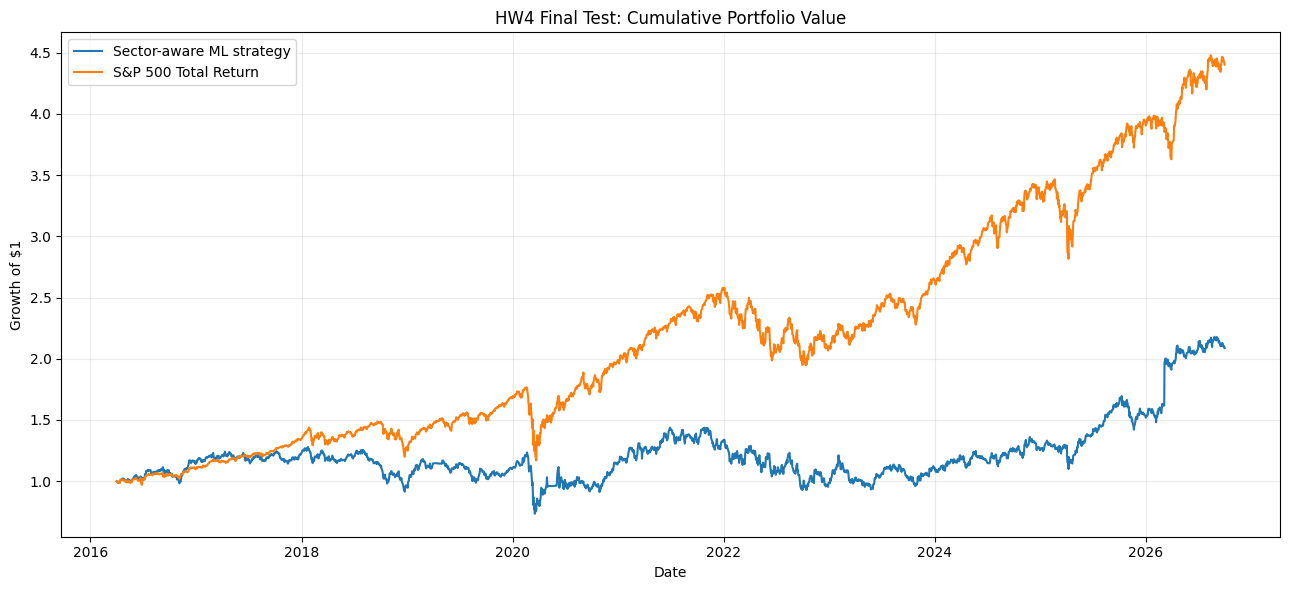

In [24]:
cumulative_strategy = portfolio_value / INITIAL_CAPITAL
cumulative_benchmark = benchmark_value / INITIAL_CAPITAL

fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(
    cumulative_strategy.index,
    cumulative_strategy.values,
    label="Sector-aware ML strategy"
)
ax.plot(
    cumulative_benchmark.index,
    cumulative_benchmark.values,
    label="S&P 500 Total Return"
)
ax.set_title("HW4 Final Test: Cumulative Portfolio Value")
ax.set_xlabel("Date")
ax.set_ylabel("Growth of $1")
ax.legend()
plt.tight_layout()
plt.show()

## 23. Daily drawdown comparison

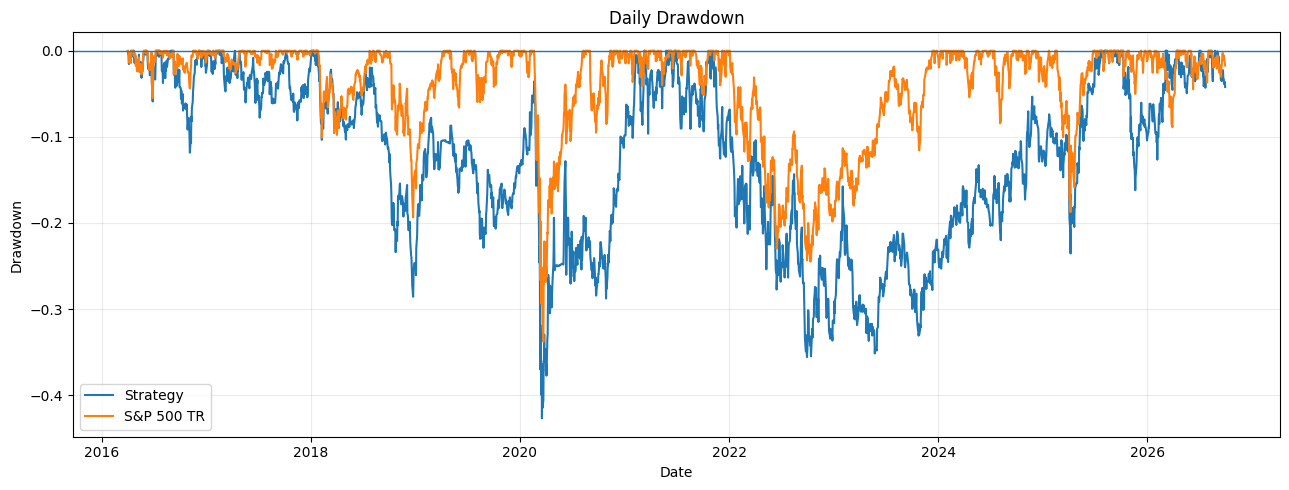

In [25]:
def drawdown_series(values, initial_value):
    values = pd.Series(values).astype(float)
    running_peak = np.maximum.accumulate(
        np.r_[initial_value, values.to_numpy()]
    )[1:]
    return pd.Series(values.to_numpy() / running_peak - 1, index=values.index)

strategy_drawdown = drawdown_series(portfolio_value, INITIAL_CAPITAL)
benchmark_drawdown = drawdown_series(benchmark_value, INITIAL_CAPITAL)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(strategy_drawdown.index, strategy_drawdown, label="Strategy")
ax.plot(benchmark_drawdown.index, benchmark_drawdown, label="S&P 500 TR")
ax.axhline(0, linewidth=1)
ax.set_title("Daily Drawdown")
ax.set_xlabel("Date")
ax.set_ylabel("Drawdown")
ax.legend()
plt.tight_layout()
plt.show()

## 24. Transaction and portfolio diagnostics

,side,events,gross_notional,transaction_fees
0,BUY,940,"49,983,309.90136","49,983.30990"
1,SELL,918,"49,082,375.58685","49,082.37559"
2,SKIP,1832,0.00000,0.00000


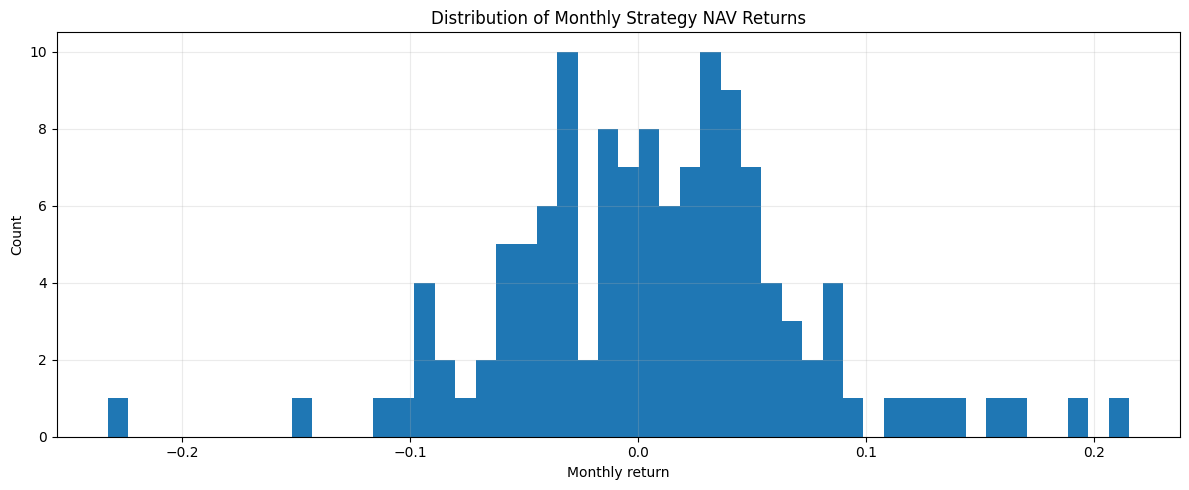

Average cash weight: 2.57%
Median open lots: 23
Total transaction fees: 99065.6854882157
Final cash: 0.0
Final holdings: 2087736.6622699525
Maximum open lots: 24
Maximum stale-mark lots: 3
Maximum pending-exit lots: 1
Maximum unresolved-maturity lots: 3


In [26]:
trade_summary = (
    trade_ledger.groupby("side")
    .agg(
        events=("side", "size"),
        gross_notional=("gross_notional", "sum"),
        transaction_fees=("transaction_fee", "sum")
    )
    .reset_index()
)

display(trade_summary)

monthly_nav = nav["portfolio_value"].resample("ME").last()
monthly_returns = monthly_nav.pct_change()

fig, ax = plt.subplots()
ax.hist(monthly_returns.dropna(), bins=50)
ax.set_title("Distribution of Monthly Strategy NAV Returns")
ax.set_xlabel("Monthly return")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

cash_weight = nav["cash"] / nav["portfolio_value"]
print("Average cash weight:", f"{cash_weight.mean():.2%}")
print("Median open lots:", int(nav["open_lots"].median()))
print("Total transaction fees:", trade_ledger["transaction_fee"].sum())
print("Final cash:", nav["cash"].iloc[-1])
print("Final holdings:", nav["holdings_value"].iloc[-1])
print("Maximum open lots:", int(nav["open_lots"].max()))
print("Maximum stale-mark lots:", int(nav["stale_mark_lots"].max()))
print("Maximum pending-exit lots:", int(nav["pending_exit_lots"].max()))
print("Maximum unresolved-maturity lots:", int(nav["unresolved_maturity_lots"].max()))

## 25. Transaction-cost sensitivity

The base strategy uses 10 bps per side. This section reruns the **same frozen orders** with 0 bps and 20 bps per side. It does not change stock picks or weights.

In [27]:
cost_sensitivity_rows = []

for cost_bps in [0.0, TRANSACTION_COST_BPS, 20.0]:
    cost_rate = cost_bps / 10_000

    nav_sens, ledger_sens, open_sens = run_daily_backtest(
        orders=planned_orders,
        test_dates=test_calendar,
        full_calendar=full_calendar,
        exact_price_matrix=exact_prices,
        mark_price_matrix=mark_prices,
        last_quote_date_matrix=last_quote_dates,
        initial_capital=INITIAL_CAPITAL,
        transaction_cost_rate=cost_rate,
        cash_rate_annual=ANNUAL_CASH_RATE,
        max_position_weight=MAX_POSITION_WEIGHT,
        max_sector_weight=MAX_SECTOR_WEIGHT,
        holding_days=HOLDING_DAYS,
        max_exit_delay_sessions=MAX_EXIT_DELAY_SESSIONS,
        initial_signal_nav={INITIAL_FIT_SIGNAL: INITIAL_CAPITAL},
        min_order_notional=MIN_ORDER_NOTIONAL
    )

    returns_sens = nav_sens["portfolio_value"].pct_change()
    returns_sens.iloc[0] = (
        nav_sens["portfolio_value"].iloc[0] / INITIAL_CAPITAL - 1
    )

    metrics_sens = performance_metrics(
        nav_sens["portfolio_value"],
        returns_sens,
        INITIAL_CAPITAL
    )

    cost_sensitivity_rows.append({
        "transaction_cost_bps_per_side": cost_bps,
        **metrics_sens,
        "total_fees": ledger_sens["transaction_fee"].sum(),
        "ending_cash": nav_sens["cash"].iloc[-1],
        "open_lots": len(open_sens)
    })

cost_sensitivity = pd.DataFrame(cost_sensitivity_rows)
display(format_metrics(cost_sensitivity))

,transaction_cost_bps_per_side,Final value,CAGR,Maximum drawdown,Daily Sharpe (rf=2%),total_fees,ending_cash,open_lots
0,0.00000,"$2,254,726.45",8.05%,-41.69%,0.358,$0.00,$0.00,22
1,10.00000,"$2,087,736.66",7.26%,-42.70%,0.328,"$99,065.69",$0.00,22
2,20.00000,"$1,933,182.53",6.48%,-43.69%,0.298,"$190,131.46",$0.00,22


## 26. Determine whether the strategy beat the benchmark

In [28]:
strategy_final = strategy_metrics["Final value"]
benchmark_final = benchmark_metrics["Final value"]

absolute_difference = strategy_final - benchmark_final
relative_difference = strategy_final / benchmark_final - 1

comparison_conclusion = {
    "strategy_final_value": strategy_final,
    "benchmark_final_value": benchmark_final,
    "absolute_difference_usd": absolute_difference,
    "relative_difference_vs_benchmark": relative_difference,
    "strategy_CAGR": strategy_metrics["CAGR"],
    "benchmark_CAGR": benchmark_metrics["CAGR"],
    "strategy_max_drawdown": strategy_metrics["Maximum drawdown"],
    "benchmark_max_drawdown": benchmark_metrics["Maximum drawdown"],
    "strategy_Sharpe": strategy_metrics["Daily Sharpe (rf=2%)"],
    "benchmark_Sharpe": benchmark_metrics["Daily Sharpe (rf=2%)"]
}

display(pd.Series(comparison_conclusion, name="value").to_frame())

if absolute_difference > 0:
    print(
        f"The strategy beat the benchmark by ${absolute_difference:,.2f} "
        f"({relative_difference:.2%} relative to benchmark final value)."
    )
elif absolute_difference < 0:
    print(
        f"The strategy underperformed the benchmark by ${-absolute_difference:,.2f} "
        f"({-relative_difference:.2%} relative to benchmark final value)."
    )
else:
    print("The strategy and benchmark ended at the same value.")

,value
strategy_final_value,"2,087,736.66227"
benchmark_final_value,"4,402,746.77627"
absolute_difference_usd,"-2,315,010.11400"
relative_difference_vs_benchmark,-0.52581
strategy_CAGR,0.07264
benchmark_CAGR,0.15166
strategy_max_drawdown,-0.42700
benchmark_max_drawdown,-0.33790
strategy_Sharpe,0.32788
benchmark_Sharpe,0.77250


The strategy underperformed the benchmark by $2,315,010.11 (52.58% relative to benchmark final value).


## 27. Save the final experiment outputs

Full outputs (ledger, daily NAV, predictions) go to the Git-ignored `Lectures/modeling/outputs/hw4_final/` directory. The cumulative-return chart and the metrics table are also saved next to this notebook so they can be included in the submission.

In [29]:
# Strategy output files
nav.to_csv(OUTPUT_DIR / "strategy_daily_nav.csv")
trade_ledger.to_csv(OUTPUT_DIR / "strategy_trade_ledger.csv", index=False)
open_lots.to_csv(OUTPUT_DIR / "strategy_open_lots_at_test_end.csv", index=False)
planned_orders.to_csv(OUTPUT_DIR / "strategy_planned_orders.csv", index=False)
walk_forward_predictions.to_csv(
    OUTPUT_DIR / "strategy_walk_forward_predictions.csv",
    index=False
)
walk_forward_fit_audit.to_csv(
    OUTPUT_DIR / "strategy_model_fit_audit.csv",
    index=False
)
performance_comparison.to_csv(
    OUTPUT_DIR / "final_performance_comparison.csv"
)
performance_comparison.to_csv(
    SUBMISSION_DIR / "final_performance_comparison.csv"
)
cost_sensitivity.to_csv(
    OUTPUT_DIR / "transaction_cost_sensitivity.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(cumulative_strategy.index, cumulative_strategy.values, label="Strategy")
ax.plot(cumulative_benchmark.index, cumulative_benchmark.values, label="S&P 500 TR")
ax.set_title("Cumulative Returns — Final Test")
ax.set_xlabel("Date")
ax.set_ylabel("Growth of $1")
ax.legend()
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "cumulative_returns.png", dpi=160, bbox_inches="tight")
fig.savefig(SUBMISSION_DIR / "cumulative_returns.png", dpi=160, bbox_inches="tight")
plt.close(fig)

FINAL_CONFIG = {
    **ASSUMPTIONS,
    "selected_model": SELECTED_MODEL_NAME,
    "training_target_clip_quantiles": list(TARGET_CLIP_QUANTILES),
    "feature_columns": FEATURE_COLUMNS,
    "validation_years": VALIDATION_YEARS,
    "test_start": str(TEST_START_ACTUAL.date()),
    "test_end": str(TEST_END_ACTUAL.date()),
    "initial_capital": INITIAL_CAPITAL,
    "risk_free_rate_annual": RISK_FREE_RATE,
    "annual_refit_dates": [str(x.date()) for x in FIT_DATES],
    "sector_warning": "Current snapshot sector labels are used for grouping; historical sector classifications are unavailable.",
    "target_warning": "Monthly 90-day cohort labels overlap and are not compounded portfolio returns.",
    "delisting_warning": "No reliable delisting proceeds table; do not infer a recovery or liquidation for inactive flags.",
}
with open(OUTPUT_DIR / "final_experiment_config.json", "w", encoding="utf-8") as f:
    json.dump(FINAL_CONFIG, f, indent=2)

print("Saved outputs:")
for output_file in sorted(OUTPUT_DIR.iterdir()):
    print(output_file.name)

Saved outputs:
cumulative_returns.png
final_experiment_config.json
final_performance_comparison.csv
full_monthly_panel.parquet
strategy_daily_nav.csv
strategy_model_fit_audit.csv
strategy_open_lots_at_test_end.csv
strategy_planned_orders.csv
strategy_trade_ledger.csv
strategy_walk_forward_predictions.csv
transaction_cost_sensitivity.csv


## 28. Final findings

### Result
The strategy **did not beat the benchmark**. $1,000,000 grew to **$2,087,737** (CAGR 7.26%), while the same amount in `^SP500TR` grew to **$4,402,747** (CAGR 15.17%). The strategy finished $2,315,010 (52.6%) below the benchmark's final value. It also took more risk: maximum drawdown −42.70% vs −33.79% (both in March 2020), annualized daily volatility 24.6% vs 17.8%, and daily Sharpe 0.33 vs 0.77 (2% risk-free rate). The strategy beat the benchmark in 2016, 2025 and 2026 (to September 30), and lagged it in the other eight calendar years, with larger losses in 2018 (−20.8% vs −4.4%) and 2022 (−26.1% vs −18.1%).

### Why it lagged
1. **Equal sector weights against a cap-weighted index.** Every sector gets the same capital, so Technology and the largest companies, which drove the index over 2016–2026, are heavily underweighted relative to `^SP500TR`, while small sectors such as Basic Materials and Utilities are overweighted.
2. **Growth picks are volatile stocks.** The highest predicted return in a sector is usually a high-volatility name, which is why the portfolio's volatility and drawdowns exceed the benchmark's.
3. **The development signal was weak.** Validation rank IC was about 0.06, and in notebook 1 the selected names did not beat an equal-weighted portfolio of all eligible stocks. The final test is consistent with that.
4. **Transaction costs are not the cause.** With zero costs the CAGR rises only to 8.05%; at 20 bps per side it is 6.48%.

### How the portfolio actually traded
- 2,772 monthly orders were planned (about 22 a month); 940 were filled and 1,832 were skipped because no cash was available. Each monthly cohort can target close to 100% of portfolio value, and lots are held for 90 days, so in practice the portfolio held one cohort of about 22–24 stocks at a time and rotated roughly every three months. Cash averaged 2.6% of portfolio value.
- Both sleeves made money on closed lots: about $603,000 for the defensive sleeve and $377,000 for the growth sleeve. 53% of closed lots were profitable.
- Total transaction costs were about $99,000.

### Accounting and data issues
- Every accounting and timing check passed: cash reconciles to the ledger, cash is never negative, every fill uses a real quote that matches the database, every buy is on the session after its signal starting April 1, 2016, every sale is within five sessions of maturity, and no price after September 30, 2026 is used.
- **Three lots matured but could never be sold**, because their prices stopped (LPI after January 2023, HOUS after January 2026, RCB after April 2026). They stay in the final value at their last observed price, $362,559 in total, or 17% of the final value. RCB alone is marked at $240,736 against a $73,247 cost, after a large price jump just before its quotes stop, which may be a data problem. Valuing the three lots at zero gives $1,725,178 (CAGR 5.33%); valuing them at cost gives $1,916,338 (CAGR 6.39%). Either way the conclusion is unchanged.

### Unsuccessful ideas and changes we would try next
- The sector-balanced, two-sleeve design was meant to reduce risk, but it produced higher volatility and deeper drawdowns than the index. Weighting sectors by their market capitalization, or ranking stocks across the whole universe, would remove the large sector bets.
- Sizing each monthly cohort at about one-third of portfolio value, so that three cohorts overlap, would use the monthly signals instead of skipping two months out of three.
- A point-in-time liquidity screen (for example, a minimum median dollar volume over the prior 63 sessions) would avoid names whose prices stop or jump unrealistically.
- Ranking stocks against each other instead of requiring a positive predicted return, since the model ranks better than it predicts return levels.
- A model trained to predict returns relative to the market or the sector, which matches how the picks are actually used.

### Main limitations
1. Sector labels are a current snapshot, not historical classifications.
2. Fundamentals are vendor latest values; filing dates do not remove restatement risk.
3. The quarterly universe is reconstructed from source records, not a certified historical constituent feed, and there are no delisting proceeds.
4. Stale marks on unsold lots can misstate the value of positions whose prices stopped.
5. The development sample had only 30 stocks, so the model choice rests on a small universe.
6. Results depend on close-price fills at the stated cost; no liquidity or market-impact model was used.